In [1]:
import os, sys
import glob
import time
import datetime as dt
from netCDF4 import Dataset
import numpy as np
from numpy.ma import masked_array
from scipy.interpolate import griddata
import metpy.calc as mpcalc
from metpy.units import units
import xarray as xr
import configparser
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from cartopy.feature import NaturalEarthFeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import warnings
from matplotlib.lines import Line2D
import datetime as dt
from datetime import datetime, timedelta
from matplotlib import colormaps
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## switch directories and read in data

In [2]:
cd /nfs/tornlab_rit/hs559346

/nfs/tornlab_rit/hs559346


In [4]:
ds3 = xr.open_dataset("diag.2023-01-05_00.00.00.nc")
ds3

<xarray.Dataset> Size: 724MB
Dimensions:                                           (time: 1, latitude: 361,
                                                       longitude: 720)
Coordinates:
  * time                                              (time) datetime64[ns] 8B ...
  * latitude                                          (latitude) float64 3kB ...
  * longitude                                         (longitude) float64 6kB ...
Data variables: (12/696)
    PRMSL_meansealevel                                (time, latitude, longitude) float32 1MB ...
    CLMR_1hybridlevel                                 (time, latitude, longitude) float32 1MB ...
    ICMR_1hybridlevel                                 (time, latitude, longitude) float32 1MB ...
    RWMR_1hybridlevel                                 (time, latitude, longitude) float32 1MB ...
    SNMR_1hybridlevel                                 (time, latitude, longitude) float32 1MB ...
    GRLE_1hybridlevel                                 (time, latitude, longitude) float32 1MB ...
    ...                                                ...
    UGRD_PV_EQ_M2eM06_Km_2_kg_s_surface               (time, latitude, longitude) float32 1MB ...
    VGRD_PV_EQ_M2eM06_Km_2_kg_s_surface               (time, latitude, longitude) float32 1MB ...
    TMP_PV_EQ_M2eM06_Km_2_kg_s_surface                (time, latitude, longitude) float32 1MB ...
    HGT_PV_EQ_M2eM06_Km_2_kg_s_surface                (time, latitude, longitude) float32 1MB ...
    PRES_PV_EQ_M2eM06_Km_2_kg_s_surface               (time, latitude, longitude) float32 1MB ...
    VWSH_PV_EQ_M2eM06_Km_2_kg_s_surface               (time, latitude, longitude) float32 1MB ...
Attributes:
    Conventions:          COARDS
    History:              created by wgrib2
    GRIB2_grid_template:  0

In [5]:
ds4 = xr.open_dataset("latlon.current.2023-01-07_00:00:00.nc")
ds4

<xarray.Dataset> Size: 968MB
Dimensions:               (Time: 1, latitude: 500, longitude: 2000,
                           nIsoLevels: 28)
Coordinates:
  * latitude              (latitude) float32 2kB 20.05 20.15 ... 69.85 69.95
  * longitude             (longitude) float32 8kB 150.1 150.2 ... 349.8 349.9
Dimensions without coordinates: Time, nIsoLevels
Data variables: (12/28)
    mslp                  (Time, latitude, longitude) float32 4MB ...
    rainnc                (Time, latitude, longitude) float32 4MB ...
    precipw               (Time, latitude, longitude) float32 4MB ...
    rainc                 (Time, latitude, longitude) float32 4MB ...
    hpbl                  (Time, latitude, longitude) float32 4MB ...
    hfx                   (Time, latitude, longitude) float32 4MB ...
    ...                    ...
    geoheight_isobaric    (Time, nIsoLevels, latitude, longitude) float32 112MB ...
    ertel_pv_isobaric     (Time, nIsoLevels, latitude, longitude) float32 112MB ...
    xtime                 (Time) |S64 64B ...
    iso_levels            (nIsoLevels) float32 112B ...
    pressure              (Time, nIsoLevels, latitude, longitude) float32 112MB ...
    ter                   (latitude, longitude) float32 4MB ...

In [4]:
member = '90_ivt_start'
member_id = 90
init_time = 2023010400

In [5]:
ds1 = xr.open_dataset(f"member{member_id}_lagranto/latlon.current.2023-01-04_00:00:00.nc")
ds = xr.open_dataset(f"member{member_id}_lagranto/forward_member{member}_2023010300.nc")
xr.set_options(display_width=10000)  # Set a very large width
#set(ds2.data_vars) - set(ds1.data_vars)
ds1

<xarray.Dataset> Size: 16GB
Dimensions:                       (Time: 8, latitude: 500, longitude: 2000, nIsoLevels: 28)
Coordinates:
  * latitude                      (latitude) float32 2kB 20.05 20.15 20.25 20.35 20.45 20.55 20.65 20.75 20.85 20.95 21.05 21.15 21.25 21.35 21.45 21.55 21.65 21.75 21.85 21.95 22.05 22.15 22.25 22.35 22.45 22.55 22.65 22.75 22.85 22.95 23.05 23.15 23.25 23.35 23.45 23.55 23.65 23.75 23.85 23.95 24.05 24.15 24.25 24.35 24.45 24.55 24.65 24.75 24.85 24.95 25.05 25.15 25.25 25.35 25.45 25.55 25.65 25.75 25.85 25.95 26.05 26.15 26.25 26.35 26.45 26.55 26.65 26.75 26.85 26.95 27.05 27.15 27.25 27.35 27.45 27.55 27.65 27.75 27.85 27.95 28.05 28.15 28.25 28.35 28.45 28.55 28.65 28.75 28.85 28.95 29.05 29.15 29.25 29.35 29.45 29.55 29.65 29.75 29.85 29.95 30.05 30.15 30.25 30.35 30.45 30.55 30.65 30.75 30.85 30.95 31.05 31.15 31.25 31.35 31.45 31.55 31.65 31.75 31.85 31.95 32.05 32.15 32.25 32.35 32.45 32.55 32.65 32.75 32.85 32.95 33.05 33.15 33.25 33.35 33.45 33.55 33.65 33.75 33.85 33.95 34.05 34.15 34.25 34.35 34.45 34.55 34.65 34.75 34.85 34.95 35.05 35.15 35.25 35.35 35.45 35.55 35.65 35.75 35.85 35.95 36.05 36.15 36.25 36.35 36.45 36.55 36.65 36.75 36.85 36.95 37.05 37.15 37.25 37.35 37.45 37.55 37.65 37.75 37.85 37.95 38.05 38.15 38.25 38.35 38.45 38.55 38.65 38.75 38.85 38.95 39.05 39.15 39.25 39.35 39.45 39.55 39.65 39.75 39.85 39.95 40.05 40.15 40.25 40.35 40.45 40.55 40.65 40.75 40.85 40.95 41.05 41.15 41.25 41.35 41.45 41.55 41.65 41.75 41.85 41.95 42.05 42.15 42.25 42.35 42.45 42.55 42.65 42.75 42.85 42.95 43.05 43.15 43.25 43.35 43.45 43.55 43.65 43.75 43.85 43.95 44.05 44.15 44.25 44.35 44.45 44.55 44.65 44.75 44.85 44.95 45.05 45.15 45.25 45.35 45.45 45.55 45.65 45.75 45.85 45.95 46.05 46.15 46.25 46.35 46.45 46.55 46.65 46.75 46.85 46.95 47.05 47.15 47.25 47.35 47.45 47.55 47.65 47.75 47.85 47.95 48.05 48.15 48.25 48.35 48.45 48.55 48.65 48.75 48.85 48.95 49.05 49.15 49.25 49.35 49.45 49.55 49.65 49.75 49.85 49.95 50.05 50.15 50.25 50.35 50.45 50.55 50.65 50.75 50.85 50.95 51.05 51.15 51.25 51.35 51.45 51.55 51.65 51.75 51.85 51.95 52.05 52.15 52.25 52.35 52.45 52.55 52.65 52.75 52.85 52.95 53.05 53.15 53.25 53.35 53.45 53.55 53.65 53.75 53.85 53.95 54.05 54.15 54.25 54.35 54.45 54.55 54.65 54.75 54.85 54.95 55.05 55.15 55.25 55.35 55.45 55.55 55.65 55.75 55.85 55.95 56.05 56.15 56.25 56.35 56.45 56.55 56.65 56.75 56.85 56.95 57.05 57.15 57.25 57.35 57.45 57.55 57.65 57.75 57.85 57.95 58.05 58.15 58.25 58.35 58.45 58.55 58.65 58.75 58.85 58.95 59.05 59.15 59.25 59.35 59.45 59.55 59.65 59.75 59.85 59.95 60.05 60.15 60.25 60.35 60.45 60.55 60.65 60.75 60.85 60.95 61.05 61.15 61.25 61.35 61.45 61.55 61.65 61.75 61.85 61.95 62.05 62.15 62.25 62.35 62.45 62.55 62.65 62.75 62.85 62.95 63.05 63.15 63.25 63.35 63.45 63.55 63.65 63.75 63.85 63.95 64.05 64.15 64.25 64.35 64.45 64.55 64.65 64.75 64.85 64.95 65.05 65.15 65.25 65.35 65.45 65.55 65.65 65.75 65.85 65.95 66.05 66.15 66.25 66.35 66.45 66.55 66.65 66.75 66.85 66.95 67.05 67.15 67.25 67.35 67.45 67.55 67.65 67.75 67.85 67.95 68.05 68.15 68.25 68.35 68.45 68.55 68.65 68.75 68.85 68.95 69.05 69.15 69.25 69.35 69.45 69.55 69.65 69.75 69.85 69.95
  * longitude                     (longitude) float32 8kB 150.1 150.2 150.2 150.4 150.4 150.6 150.7 150.8 150.8 150.9 151.0 151.2 151.2 151.4 151.4 151.6 151.7 151.8 151.9 151.9 152.1 152.2 152.2 152.3 152.4 152.6 152.7 152.8 152.9 152.9 153.1 153.2 153.2 153.4 153.4 153.5 153.6 153.8 153.9 153.9 154.1 154.2 154.2 154.4 154.4 154.6 154.7 154.7 154.8 154.9 155.1 155.2 155.2 155.3 155.4 155.6 155.7 155.8 155.9 155.9 156.0 156.1 156.2 156.4 156.4 156.5 156.6 156.8 156.9 156.9 157.1 157.2 157.2 157.4 157.4 157.6 157.7 157.7 157.8 157.9 158.0 158.2 158.2 158.4 158.4 158.6 158.7 158.8 158.9 158.9 159.1 159.2 159.2 159.3 159.4 159.6 159.7 159.8 159.9 159.9 160.1 160.2 160.2 160.4 160.4 160.5 160.7 160.8 160.9 160.9 161.1 161.1 161.2 161.4 161.4 161.6 161.7 161.7 161.8 161.9 162.1 162.2 162.2 162.3 162.4 16

In [46]:
all_indices = np.arange(ds.dims['ntra'])

# Domain boundaries from target_domain
# Note: lon in target_domain is 150-285, but trajectories likely use -180 to 180
startlat = 20
endlat   = 70
startlon = 150  # convert to -210, or adjust based on your coordinate system
endlon   = 330 # convert to -75

# Create a mask for trajectories that stay within the domain
def within_domain(ds, indices, startlat, endlat, startlon, endlon):
    lat = ds.lat[:, indices].values  # shape: (ntim, n_traj)
    lon = ds.lon[:, indices].values

    # Check if any time step goes outside the domain
    outside = (
        (lat < startlat) | (lat > endlat) |
        (lon < startlon) | (lon > endlon)
    )  # shape: (ntim, n_traj)

    # True for trajectories that stay inside the domain at ALL time steps
    inside_mask = ~outside.any(axis=0)  # shape: (n_traj,)
    return inside_mask

inside_mask = within_domain(ds, all_indices, startlat=20, endlat=70, startlon=150, endlon=330)
print(f"Trajectories removed: {(~inside_mask).sum()}")
print(f"Trajectories remaining: {inside_mask.sum()}")

# Filter all_indices to only include trajectories within the domain
all_indices = all_indices[inside_mask]

Trajectories removed: 11
Trajectories remaining: 574


/tmp/ipykernel_37284/3041893879.py:1: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  all_indices = np.arange(ds.dims['ntra'])


In [47]:
height = ds.z.values
height_levels = [500, 1000, 1500, 2000, 2500]
height_cmap = plt.cm.rainbow
height_norm = mcolors.BoundaryNorm(boundaries=[250, 750, 1250, 1750, 2250, 2750], ncolors=256)

# assign time of plotting
starting_time = dt.datetime(
    ds.attrs['ref_year'],
    ds.attrs['ref_month'],
    ds.attrs['ref_day'],
    ds.attrs['ref_hour'],
    ds.attrs['ref_min']
)

#####__________#####
traj_init_time = starting_time+timedelta(hours=24)
#####__________#####
formatted_time = traj_init_time.strftime('%Y-%m-%d %H:%M UTC')

## Trajectories at individual starting heights

/tmp/ipykernel_28135/3840055161.py:16: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for tr in range(ds.dims['ntra']):


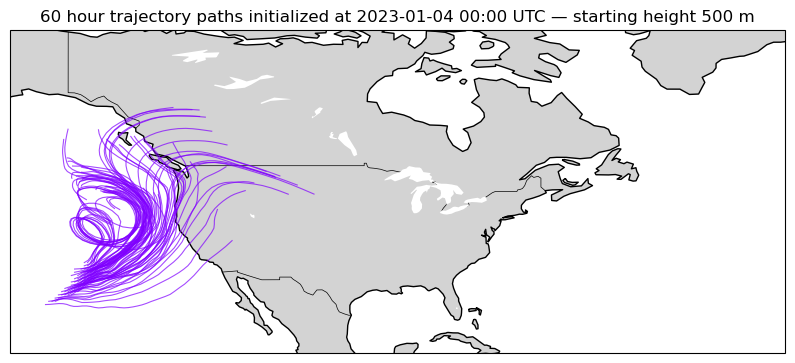

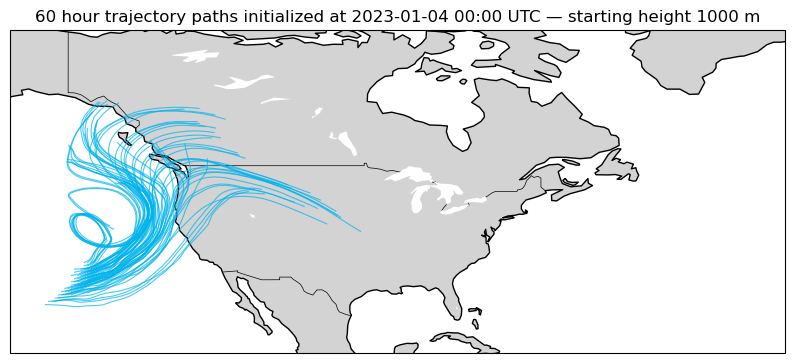

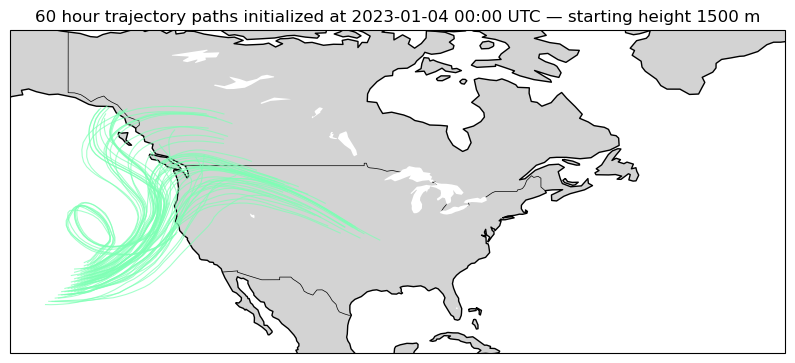

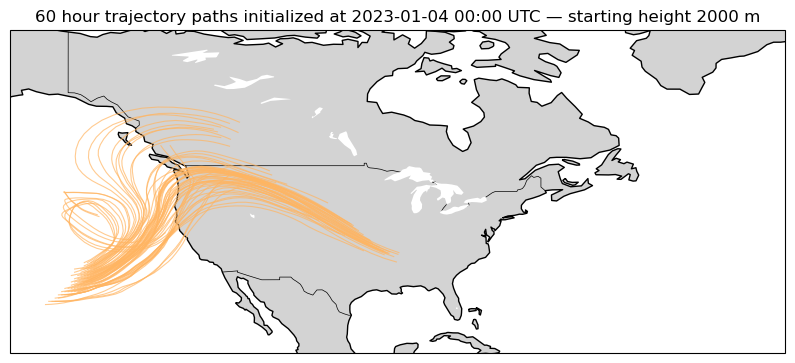

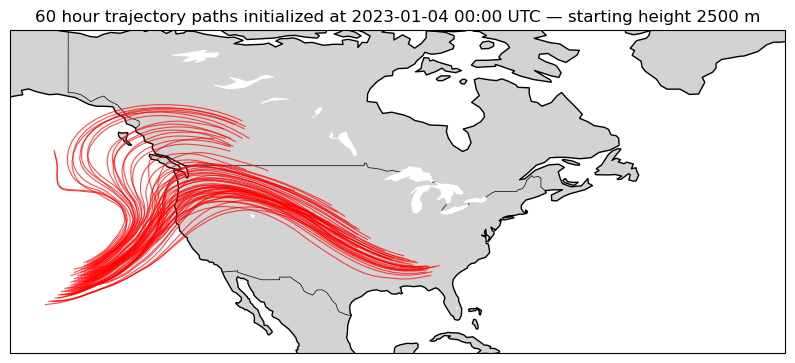

In [8]:
import matplotlib.colors as mcolors
import warnings

for height in height_levels:
    fig = plt.figure(figsize=(10, 7))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='white')
    ax.add_feature(cfeature.LAKES, facecolor='white')
    #####__________#####
    ax.set_extent([-30, -150, 20, 70], crs=ccrs.PlateCarree())
    #####__________#####

    for tr in range(ds.dims['ntra']):
        lat = ds.lat[:, tr].values
        lon = ds.lon[:, tr].values
        z   = ds.z[:, tr].values
        start_z = z[0]

        # only plot one height level for each plot
        if start_z != height:
            continue

        ax.plot(lon, lat, linewidth=0.8, alpha=0.7,
                transform=ccrs.PlateCarree(),
                color=height_cmap(height_norm(start_z)))

    ax.set_title(f'60 hour trajectory paths initialized at {formatted_time} — starting height {height} m')
    warnings.filterwarnings("ignore")
    #plt.savefig(f"{init_time}_trajectory_plots_member{member}/trajectories_{height}m.png")
    #plt.show()
    #plt.close(fig)

## PV Tendencies Panel

In [9]:
total_diabatic_tendency = (ds.acc_depv_dt_lw_isobaric + ds.acc_depv_dt_sw_isobaric + ds.acc_depv_dt_bl_isobaric
                  + ds.acc_depv_dt_cu_isobaric + ds.acc_depv_dt_mp_isobaric)
latent_heat_release = ds.acc_depv_dt_cu_isobaric + ds.acc_depv_dt_mp_isobaric
total_diabatic_tendency_with_friction = (ds.acc_depv_dt_lw_isobaric + ds.acc_depv_dt_sw_isobaric + ds.acc_depv_dt_bl_isobaric
                                + ds.acc_depv_dt_cu_isobaric + ds.acc_depv_dt_mp_isobaric + ds.acc_depv_dt_fric_bl_isobaric)

ds['total_diabatic_tendency'] = total_diabatic_tendency
ds['latent_heat_release'] = latent_heat_release
ds['total_diabatic_tendency_with_friction'] = total_diabatic_tendency_with_friction

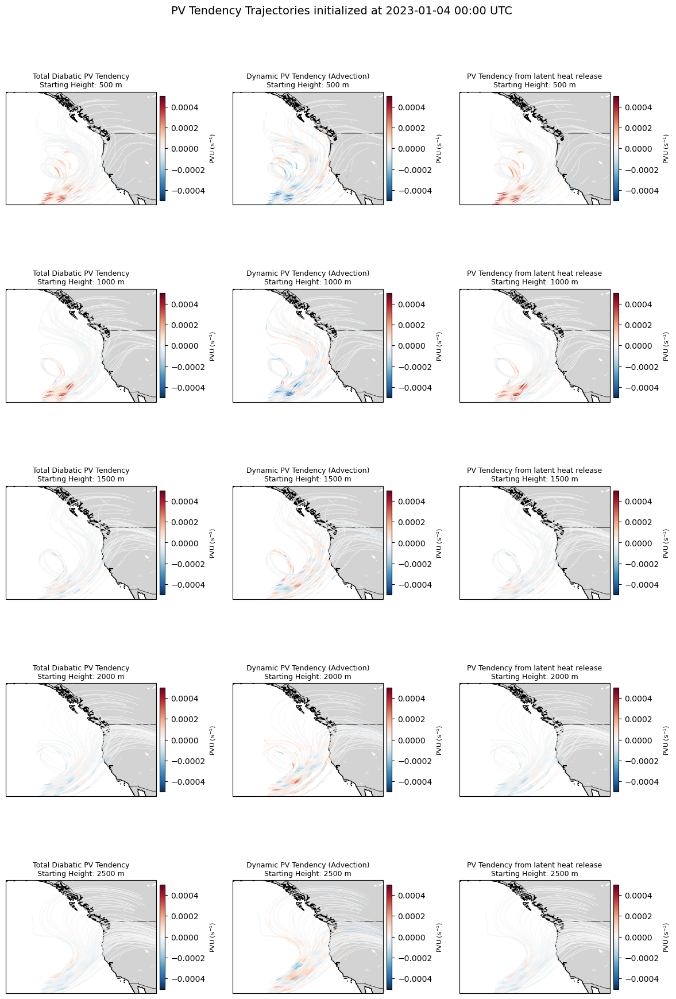

In [10]:
from matplotlib.collections import LineCollection

# Define variables and their properties
variables = {
    'total_diabatic_tendency': {'label': 'Total Diabatic PV Tendency', 'cmap': plt.cm.RdBu_r, 'vmin': -.0005, 'vmax': .0005},
    'acc_depv_dt_dyn_isobaric': {'label': 'Dynamic PV Tendency (Advection)','cmap': plt.cm.RdBu_r, 'vmin': -.0005, 'vmax': .0005},
    'latent_heat_release':      {'label': 'PV Tendency from latent heat release','cmap': plt.cm.RdBu_r, 'vmin': -.0005, 'vmax': .0005},
}

n_rows = len(height_levels)   # 5
n_cols = len(variables)       # 3

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(12, 18),
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for row, height in enumerate(height_levels):
    for col, (var_name, var_props) in enumerate(variables.items()):
        ax = axes[row, col]

        ax.add_feature(cfeature.COASTLINE)
        ax.add_feature(cfeature.BORDERS, linewidth=0.5)
        ax.add_feature(cfeature.LAND, facecolor='lightgray')
        ax.add_feature(cfeature.OCEAN, facecolor='white')
        ax.add_feature(cfeature.LAKES, facecolor='white')
        ax.set_extent([-110, -150, 30, 60], crs=ccrs.PlateCarree())

        var_cmap = var_props['cmap']
        var_norm = plt.Normalize(vmin=var_props['vmin'], vmax=var_props['vmax'])

        for tr in range(ds.dims['ntra']):
            lat = ds.lat[:, tr].values
            lon = ds.lon[:, tr].values
            z   = ds.z[:, tr].values
            start_z = z[0]

            if start_z != height:
                continue

            var_vals = ds[var_name][:, tr].values

            # Build line segments
            points = np.array([lon, lat]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]], axis=1)
            var_mid = (var_vals[:-1] + var_vals[1:]) / 2

            lc = LineCollection(segments, cmap=var_cmap, norm=var_norm,
                                linewidth=0.8, alpha=0.7,
                                transform=ccrs.PlateCarree())
            lc.set_array(var_mid)
            ax.add_collection(lc)

        # Colorbar for each panel
        sm = plt.cm.ScalarMappable(cmap=var_cmap, norm=var_norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, orientation='vertical', pad=0.02, shrink=0.5)
        cbar.set_label('PVU (s$^{-1}$)', fontsize=8)

        ax.set_title(f'{var_props["label"]}\nStarting Height: {height} m', fontsize=9)

warnings.filterwarnings("ignore")
plt.suptitle(f'PV Tendency Trajectories initialized at {formatted_time}', 
             fontsize=14, y=1.01)
plt.tight_layout()
#plt.savefig(f"{init_time}_trajectory_plots_member{member}/trajectory_pv_tendencies_panel.png",
            #dpi=150, bbox_inches='tight')
plt.show()
#plt.close(fig)

## Time series Plots

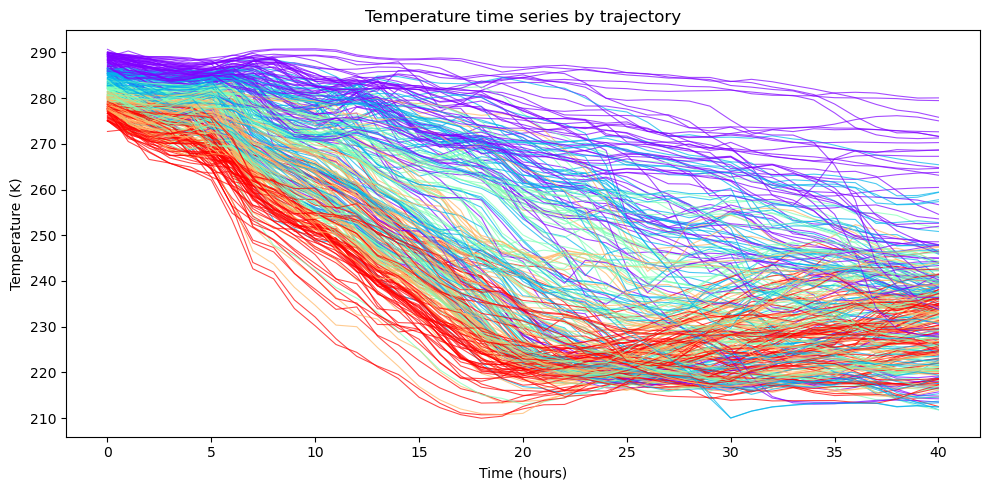

In [11]:
height_cmap = plt.cm.rainbow
height_norm = mcolors.BoundaryNorm(boundaries=[250, 750, 1250, 1750, 2250, 2750], ncolors=256)

fig, ax = plt.subplots(figsize=(10, 5))

for tr in range(ds.dims['ntra']):
    temp = ds.temperature_isobaric[:, tr].values  # shape: (ntim,)
    start_z = ds.z[:, tr].values[0]  # starting height of this trajectory

    color = height_cmap(height_norm(start_z))
    ax.plot(ds.time.values - 24, temp, color=color, linewidth=0.8, alpha=0.7)

ax.set_xlabel('Time (hours)')
ax.set_ylabel('Temperature (K)')
ax.set_title('Temperature time series by trajectory')
plt.tight_layout()
#plt.savefig(f"{init_time}_trajectory_plots_member{member}/temperature_time_series.png")
#plt.close(fig)

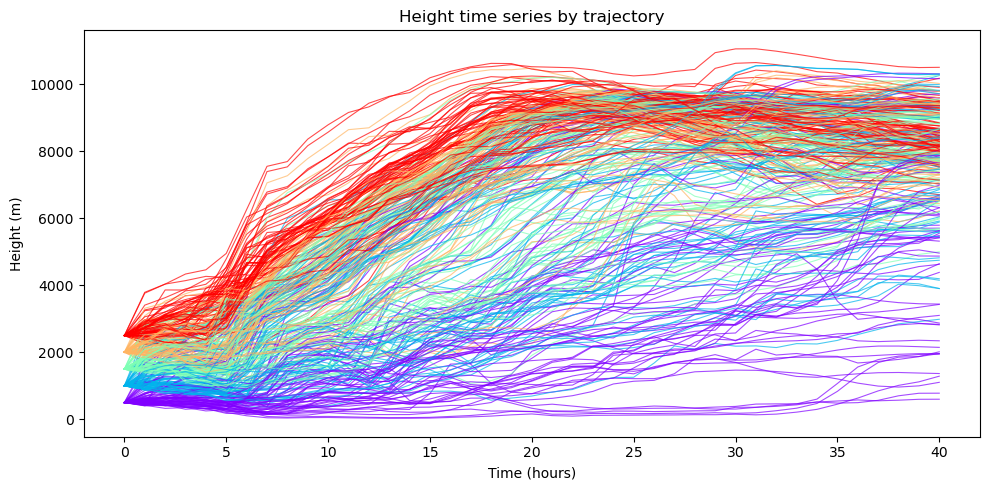

In [12]:
height_cmap = plt.cm.rainbow
height_norm = mcolors.BoundaryNorm(boundaries=[250, 750, 1250, 1750, 2250, 2750], ncolors=256)

fig, ax = plt.subplots(figsize=(10, 5))

for tr in range(ds.dims['ntra']):
    height = ds.z[:, tr].values  # shape: (ntim,)
    start_z = height[0]  # starting height of this trajectory

    color = height_cmap(height_norm(start_z))
    ax.plot(ds.time.values - 24, height, color=color, linewidth=0.8, alpha=0.7)

ax.set_xlabel('Time (hours)')
ax.set_ylabel('Height (m)')
ax.set_title('Height time series by trajectory')
plt.tight_layout()
#plt.savefig(f"{init_time}_trajectory_plots_member{member}/height_time_series.png")
#plt.close(fig)

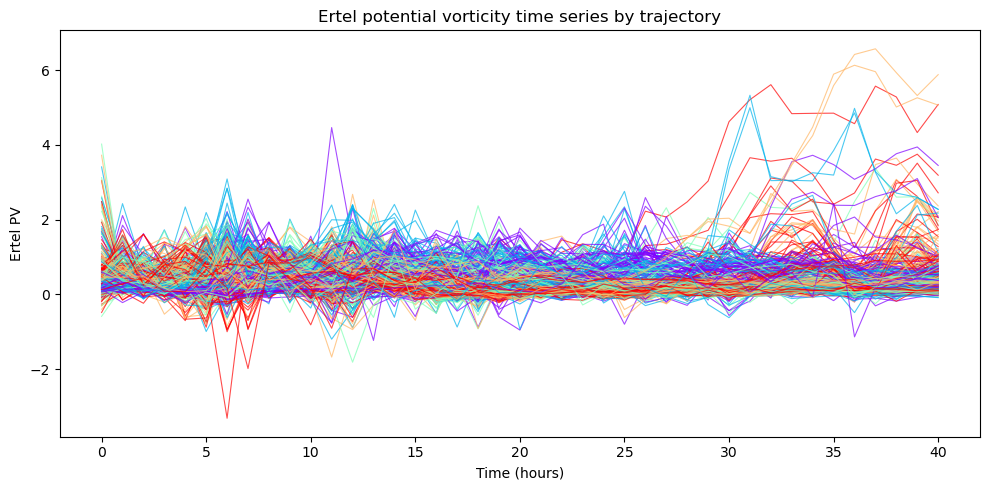

In [13]:
height_cmap = plt.cm.rainbow
height_norm = mcolors.BoundaryNorm(boundaries=[250, 750, 1250, 1750, 2250, 2750], ncolors=256)

fig, ax = plt.subplots(figsize=(10, 5))

for tr in range(ds.dims['ntra']):
    pv = ds.ertel_pv_isobaric[:, tr].values  # shape: (ntim,)
    start_z = ds.z[:, tr].values[0]  # starting height of this trajectory

    color = height_cmap(height_norm(start_z))
    ax.plot(ds.time.values - 24, pv, color=color, linewidth=0.8, alpha=0.7)

ax.set_xlabel('Time (hours)')
ax.set_ylabel('Ertel PV')
ax.set_title('Ertel potential vorticity time series by trajectory')
plt.tight_layout()
# plt.savefig(f"{init_time}_trajectory_plots_member{member}/ertel_pv_time_series.png")
# plt.close(fig)

# K-means clustering grouped by starting height, clustered on location

In [14]:
# # regular flatten function clusterng by raw height
# def latlon_to_km(lat, lon):
#     """Convert lat/lon arrays to approximate x/y distances in km relative to domain mean"""
#     lat_ref = np.mean(lat)
#     lon_ref = np.mean(lon)
    
#     km_per_deg_lat = 111.0
#     km_per_deg_lon = 111.0 * np.cos(np.radians(lat_ref))
    
#     x = (lon - lon_ref) * km_per_deg_lon  # km in east-west direction
#     y = (lat - lat_ref) * km_per_deg_lat  # km in north-south direction
#     return x, y

# def flatten(ds, indices):
#     """Convert lat/lon data to 1D vectors which are easy to cluster using the approximate x/y distances"""
#     lat = ds.lat[:, indices].values  # shape: (ntim, n_traj)
#     lon = ds.lon[:, indices].values

#     x, y = latlon_to_km(lat, lon)

#     # Flatten each trajectory to a 1D feature vector: [lat0, lat1, ..., lon0, lon1, ...]
#     features = np.concatenate([x.T, y.T], axis=1)
#     return features

# x, y = latlon_to_km(lat, lon)
# #print(ds.lat[:, 0].values)

In [15]:
# # elbow plots
# fig, axes = plt.subplots(1, len(height_levels), figsize=(20, 4))

# inertias_by_height = {}

# for ax, h in zip(axes, height_levels):
#     indices = height_groups[h]
#     features = flatten(ds, indices)
#     scaler = StandardScaler()                         # these two lines normalize the matrix, since distances are used to
#     features_scaled = scaler.fit_transform(features)  # calculate the clusters

#     inertias = []
#     k_range = range(1, min(11, len(indices)))  # up to 10 clusters
#     for k in k_range:
#         km = KMeans(n_clusters=k, random_state=42, n_init=10)
#         km.fit(features_scaled)
#         inertias.append(km.inertia_)

#     inertias_by_height[h] = (features_scaled, inertias)

#     ax.plot(k_range, inertias, 'o-')
#     ax.set_title(f'Elbow Plot: {h} m')
#     ax.set_xlabel('Number of Clusters (k)')
#     ax.set_ylabel('Inertia')
#     ax.grid(True)

# plt.tight_layout()
# plt.show()

In [16]:
# # Group trajectory indices by starting height
# from sklearn.cluster import KMeans
# from sklearn.preprocessing import StandardScaler
# from scipy.cluster.hierarchy import dendrogram, linkage
# import pandas as pd

# height_levels = [500, 1000, 1500, 2000, 2500]

# # Get starting height for each trajectory
# start_z = ds.z[0, :].values  # shape: (405,)


# height_groups = {}
# for h in height_levels:
#     mask = start_z == h
#     height_groups[h] = np.where(mask)[0]
#     #print(f"{h} m: {mask.sum()} trajectories")
# #print(height_groups)

## Cluster maps by height with raw height

In [17]:
# cluster_cmap = plt.cm.tab10  # has 10 distinct colors at fixed positions
# cluster_colors = [cluster_cmap(i) for i in range(10)]  # always the same 10 colors

# # Choose k for each height level based on your elbow plots/dendrograms
# k_by_height = {500: 3, 1000: 2, 1500: 3, 2000: 3, 2500: 3}  # adjust as needed

# for h in height_levels:
#     indices = height_groups[h]
#     features = flatten(ds, indices)
#     scaler = StandardScaler()
#     features_scaled = scaler.fit_transform(features)
#     k = k_by_height[h]
#     km = KMeans(n_clusters=k, random_state=42, n_init=10)
#     labels = km.fit_predict(features_scaled)

#     # Set up cluster colors
#     color = cluster_colors[labels[i]]

#     fig = plt.figure(figsize=(10, 7))
#     ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
#     ax.add_feature(cfeature.COASTLINE)
#     ax.add_feature(cfeature.BORDERS, linewidth=0.5)
#     ax.add_feature(cfeature.LAND, facecolor='lightgray')
#     ax.add_feature(cfeature.OCEAN, facecolor='white')
#     ax.add_feature(cfeature.LAKES, facecolor='white')
#     ax.set_extent([-110, -150, 30, 60], crs=ccrs.PlateCarree())

#     for cluster_id in range(k):
#         # Get indices of trajectories in this cluster
#         cluster_mask = labels == cluster_id
#         cluster_traj_indices = indices[cluster_mask]

#         # Compute mean lat/lon across all trajectories in this cluster
#         mean_lat = ds.lat[:, cluster_traj_indices].values.mean(axis=1)  # shape: (ntim,)
#         mean_lon = ds.lon[:, cluster_traj_indices].values.mean(axis=1)

#         ax.plot(mean_lon, mean_lat, color=cluster_colors[cluster_id],
#                 linewidth=3, linestyle='--', alpha=0.9, transform=ccrs.PlateCarree())

#     for i, tr in enumerate(indices):
#         lat = ds.lat[:, tr].values
#         lon = ds.lon[:, tr].values
#         color = cluster_colors[labels[i]]

#         ax.plot(lon, lat, color=color, linewidth=0.8, alpha=0.6,
#                 transform=ccrs.PlateCarree())

#     # Build legend entries for each cluster
#     legend_elements = [
#     plt.Line2D([0], [0], color=cluster_colors[i], linewidth=2, label=f'Cluster {i+1}')
#     for i in range(k)
# ]
#     ax.legend(handles=legend_elements, title='Cluster', loc='lower left', frameon=True)

#     ax.set_title(f'Trajectory Clusters at {h} m')
#     plt.savefig(f"{init_time}_trajectory_plots_member{member}/trajectory_clusters_{h}.png")
#     plt.close(fig)

## Cluster mean maps by height

In [18]:
# for h in height_levels:
#     indices = height_groups[h]
#     features = flatten(ds, indices)
#     scaler = StandardScaler()
#     features_scaled = scaler.fit_transform(features)
#     k = k_by_height[h]
#     km = KMeans(n_clusters=k, random_state=42, n_init=10)
#     labels = km.fit_predict(features_scaled)

#     fig = plt.figure(figsize=(10, 7))
#     ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
#     ax.add_feature(cfeature.COASTLINE)
#     ax.add_feature(cfeature.BORDERS, linewidth=0.5)
#     ax.add_feature(cfeature.LAND, facecolor='lightgray')
#     ax.add_feature(cfeature.OCEAN, facecolor='white')
#     ax.add_feature(cfeature.LAKES, facecolor='white')
#     ax.set_extent([-110, -150, 30, 60], crs=ccrs.PlateCarree())

#     for cluster_id in range(k):
#         # Get indices of trajectories in this cluster
#         cluster_mask = labels == cluster_id
#         cluster_traj_indices = indices[cluster_mask]

#         # Compute mean lat/lon across all trajectories in this cluster
#         mean_lat = ds.lat[:, cluster_traj_indices].values.mean(axis=1)  # shape: (ntim,)
#         mean_lon = ds.lon[:, cluster_traj_indices].values.mean(axis=1)

#         ax.plot(mean_lon, mean_lat, color=cluster_colors[cluster_id],
#                 linewidth=2, alpha=0.9, transform=ccrs.PlateCarree())

#     legend_elements = [
#         plt.Line2D([0], [0], color=cluster_colors[i], linewidth=2, label=f'Cluster {i+1}')
#         for i in range(k)
#     ]
#     ax.legend(handles=legend_elements, title='Cluster', loc='lower left', frameon=True)
#     ax.set_title(f'Trajectory Cluster Means at {h} m')
#     plt.savefig(f"{init_time}_trajectory_plots_member{member}/trajectory_cluster_means_{h}.png")
#     plt.close(fig)

## Cluster time series by height

In [19]:
# for h in height_levels:
#     indices = height_groups[h]
#     features = flatten(ds, indices)
#     scaler = StandardScaler()
#     features_scaled = scaler.fit_transform(features)
#     k = k_by_height[h]
#     km = KMeans(n_clusters=k, random_state=42, n_init=10)
#     labels = km.fit_predict(features_scaled)

#     fig, ax = plt.subplots(figsize=(10, 5))

#     for cluster_id in range(k):
#         cluster_mask = labels == cluster_id
#         cluster_traj_indices = indices[cluster_mask]
#         mean_temp = ds.temperature_isobaric[:, cluster_traj_indices].values.mean(axis=1)
#         ax.plot(ds.time.values - 24, mean_temp, color=cluster_colors[cluster_id],
#                 linewidth=3, alpha=1.0, linestyle='--')

#     for i, tr in enumerate(indices):
#         temp = ds.temperature_isobaric[:, tr].values
#         color = cluster_colors[labels[i]]
#         ax.plot(ds.time.values - 24, temp, color=color, linewidth=0.8, alpha=0.6)

#     legend_elements = [
#         plt.Line2D([0], [0], color=cluster_colors[i], linewidth=2, label=f'Cluster {i+1}')
#         for i in range(k)
#     ]
#     ax.legend(handles=legend_elements, title='Cluster', loc='upper right', frameon=True)
#     ax.set_xlabel('Time (hours)')
#     ax.set_ylabel('Temperature (K)')
#     ax.set_title(f'Temperature time series by cluster at {h} m')
#     plt.tight_layout()
#     plt.savefig(f"{init_time}_trajectory_plots_member{member}/temperature_time_series_clusters_{h}.png")
#     plt.close(fig)

In [20]:
# for h in height_levels:
#     indices = height_groups[h]
#     features = flatten(ds, indices)
#     scaler = StandardScaler()
#     features_scaled = scaler.fit_transform(features)
#     k = k_by_height[h]
#     km = KMeans(n_clusters=k, random_state=42, n_init=10)
#     labels = km.fit_predict(features_scaled)

#     fig, ax = plt.subplots(figsize=(10, 5))

#     for cluster_id in range(k):
#         cluster_mask = labels == cluster_id
#         cluster_traj_indices = indices[cluster_mask]
#         mean_height = ds.z[:, cluster_traj_indices].values.mean(axis=1)
#         ax.plot(ds.time.values - 24, mean_height, color=cluster_colors[cluster_id],
#                 linewidth=3, alpha=1.0, linestyle='--')

#     for i, tr in enumerate(indices):
#         height = ds.z[:, tr].values
#         color = cluster_colors[labels[i]]
#         ax.plot(ds.time.values - 24, height, color=color, linewidth=0.8, alpha=0.6)

#     legend_elements = [
#         plt.Line2D([0], [0], color=cluster_colors[i], linewidth=2, label=f'Cluster {i+1}')
#         for i in range(k)
#     ]
#     ax.legend(handles=legend_elements, title='Cluster', loc='upper right', frameon=True)
#     ax.set_xlabel('Time (hours)')
#     ax.set_ylabel('Height (m)')
#     ax.set_title(f'Height time series by cluster at {h} m')
#     plt.tight_layout()
#     plt.savefig(f"{init_time}_trajectory_plots_member{member}/height_time_series_clusters_{h}.png")
#     plt.close(fig)

In [21]:
# for h in height_levels:
#     indices = height_groups[h]
#     features = flatten(ds, indices)
#     scaler = StandardScaler()
#     features_scaled = scaler.fit_transform(features)
#     k = k_by_height[h]
#     km = KMeans(n_clusters=k, random_state=42, n_init=10)
#     labels = km.fit_predict(features_scaled)

#     fig, ax = plt.subplots(figsize=(10, 5))

#     for cluster_id in range(k):
#         cluster_mask = labels == cluster_id
#         cluster_traj_indices = indices[cluster_mask]
#         pv = ds.ertel_pv_isobaric[:, cluster_traj_indices].values.mean(axis=1)
#         ax.plot(ds.time.values - 24, pv, color=cluster_colors[cluster_id],
#                 linewidth=3, alpha=1.0, linestyle='--')

#     for i, tr in enumerate(indices):
#         pv = ds.ertel_pv_isobaric[:, tr].values
#         color = cluster_colors[labels[i]]
#         ax.plot(ds.time.values - 24, pv, color=color, linewidth=0.8, alpha=0.6)

#     legend_elements = [
#         plt.Line2D([0], [0], color=cluster_colors[i], linewidth=2, label=f'Cluster {i+1}')
#         for i in range(k)
#     ]
#     ax.legend(handles=legend_elements, title='Cluster', loc='upper right', frameon=True)
#     ax.set_xlabel('Time (hours)')
#     ax.set_ylabel('Ertel PV (PVU)')
#     ax.set_title(f'Ertel PV time series by cluster at {h} m')
#     plt.tight_layout()
#     plt.savefig(f"{init_time}_trajectory_plots_member{member}/ertel_pv_time_series_clusters_{h}.png")
#     plt.close(fig)

# K-means clustering by location and height

### Only run one of the two cells below:

In [22]:
# regular flatten function using location and raw height
def flatten(ds, indices, z_weight=1):
    lat = ds.lat[2:36, indices].values  # first 36 hours, skipping first 2 time steps
    lon = ds.lon[2:36, indices].values
    z   = ds.z[2:36, indices].values

    # Convert lat/lon to km
    lat_ref = np.mean(lat)
    lon_ref = np.mean(lon)
    km_per_deg_lat = 111.0
    km_per_deg_lon = 111.0 * np.cos(np.radians(lat_ref))

    # Convert to a distance from the mean point in km
    x = (lon - lon_ref) * km_per_deg_lon  # (ntim, n_traj)
    y = (lat - lat_ref) * km_per_deg_lat

    xy = np.concatenate([x.T, y.T], axis=1)   # (n_traj, 2*ntim)
    z_flat = z.T                                # (n_traj, ntim)

    # Scale each variable group independently
    xy_scaled = StandardScaler().fit_transform(xy)
    z_scaled  = StandardScaler().fit_transform(z_flat) * z_weight

    # Flatten each trajectory: [x0..xn, y0..yn, z0..zn]
    features = np.concatenate([xy_scaled, z_scaled], axis=1)
    return features

In [23]:
# updated flatten function which clusters by location as well as CHANGE IN HEIGHT
def flatten(ds, indices, z_weight):
    lat = ds.lat[2:36, indices].values  # first 36 hours, skipping first 2 time steps
    lon = ds.lon[2:36, indices].values
    z   = ds.z[2:36, indices].values

    # Subtract starting height so z represents change relative to start
    z_start = ds.z[0, indices].values  # shape: (n_traj,)
    z_rel = z - z_start[np.newaxis, :]  # broadcast across time steps, shape: (ntim, n_traj)

    lat_ref = np.mean(lat)
    lon_ref = np.mean(lon)
    km_per_deg_lat = 111.0
    km_per_deg_lon = 111.0 * np.cos(np.radians(lat_ref))

    x = (lon - lon_ref) * km_per_deg_lon
    y = (lat - lat_ref) * km_per_deg_lat

    scaler_xy = StandardScaler()
    scaler_z  = StandardScaler()

    xy = np.concatenate([x.T, y.T], axis=1)
    z_flat = z_rel.T  # use relative height instead of absolute height

    xy_scaled = scaler_xy.fit_transform(xy)
    z_scaled  = scaler_z.fit_transform(z_flat) * z_weight

    features = np.concatenate([xy_scaled, z_scaled], axis=1)
    return features

In [24]:
# clustering and color-assigning code - function ensures cluster colors are consistent across different numbers of clusters
from scipy.optimize import linear_sum_assignment

scaler = StandardScaler()

z_weight = 0.8
all_indices = all_indices[inside_mask]
features = flatten(ds, all_indices, z_weight)

def get_stable_labels(features, k, prev_raw_labels=None, prev_color_map=None):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    raw_labels = km.fit_predict(features)  # raw KMeans output, indices 0..k-1

    if prev_raw_labels is None:
        mean_lons = np.array([
            ds.lon[:, all_indices[raw_labels == c]].values.mean()
            for c in range(k)
        ])
        order = np.argsort(mean_lons)
        remap = np.empty_like(order)
        remap[order] = np.arange(k)
        raw_labels_remapped = remap[raw_labels]
        color_map = {c: c for c in range(k)}
        return raw_labels_remapped, raw_labels_remapped.copy(), color_map

    prev_k = len(np.unique(prev_raw_labels))
    new_k = k

    # Build overlap using raw labels on BOTH sides (both are 0..k-1 indices)
    overlap = np.zeros((new_k, prev_k), dtype=int)
    for i in range(len(raw_labels)):
        overlap[raw_labels[i], prev_raw_labels[i]] += 1

    row_ind, col_ind = linear_sum_assignment(-overlap)

    new_color_map = {}
    used_colors = set(prev_color_map.values())

    for new_c, prev_c in zip(row_ind, col_ind):
        new_color_map[new_c] = prev_color_map[prev_c]

    for new_c in range(new_k):
        if new_c not in new_color_map:
            next_color = max(used_colors) + 1
            new_color_map[new_c] = next_color
            used_colors.add(next_color)

    remapped = np.array([new_color_map[l] for l in raw_labels])
    return remapped, raw_labels.copy(), new_color_map  # return raw too


# Assign consistent colors to clusters
prev_raw_labels, prev_color_map = None, None
results = {}

for k in [3, 4, 5, 6]:
    labels, raw_labels, color_map = get_stable_labels(
        features, k, prev_raw_labels, prev_color_map
    )
    results[k] = labels
    prev_raw_labels = raw_labels   # <-- pass raw, not remapped
    prev_color_map = color_map
    #print(f"k={k}: color_map = {color_map}")

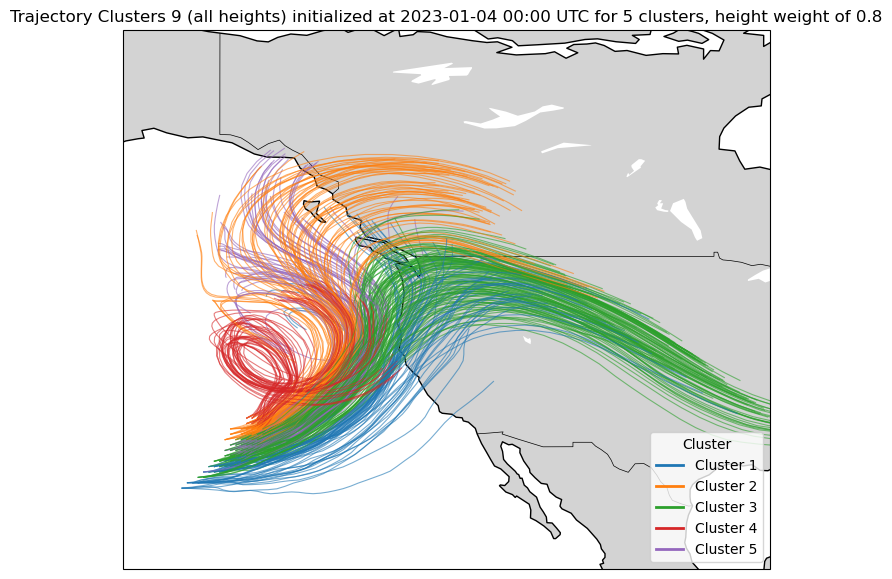

In [40]:
cluster_cmap = plt.cm.tab10  # has 10 distinct colors at fixed positions
cluster_colors = [cluster_cmap(i) for i in range(10)]  # always the same 10 colors

for k in [5]:
    fig = plt.figure(figsize=(10, 7))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='white')
    ax.add_feature(cfeature.LAKES, facecolor='white')
    ax.set_extent([-90, -150, 20, 70], crs=ccrs.PlateCarree())

    for i, tr in enumerate(all_indices):
        lat = ds.lat[:, tr].values
        lon = ds.lon[:, tr].values
    
        # Set up cluster colors
        labels = results[k]
        
        ax.plot(lon, lat, color=cluster_colors[labels[i]],
                linewidth=0.8, alpha=0.6, transform=ccrs.PlateCarree())
    
    # Legend: only show color indices that appear in this k
    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    
    ax.legend(handles=legend_elements, title='Cluster', loc='lower right', frameon=True)
    ax.set_title(f'Trajectory Clusters {member_id} (all heights) initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    #####__________#####
    #plt.savefig(f"{init_time}_trajectory_plots_member{member}/trajectory_clusters_all_heights_{k}_change_in_height,_z_weight={z_weight}.png",
                #dpi=150, bbox_inches='tight')
    #####__________#####
    #plt.close()

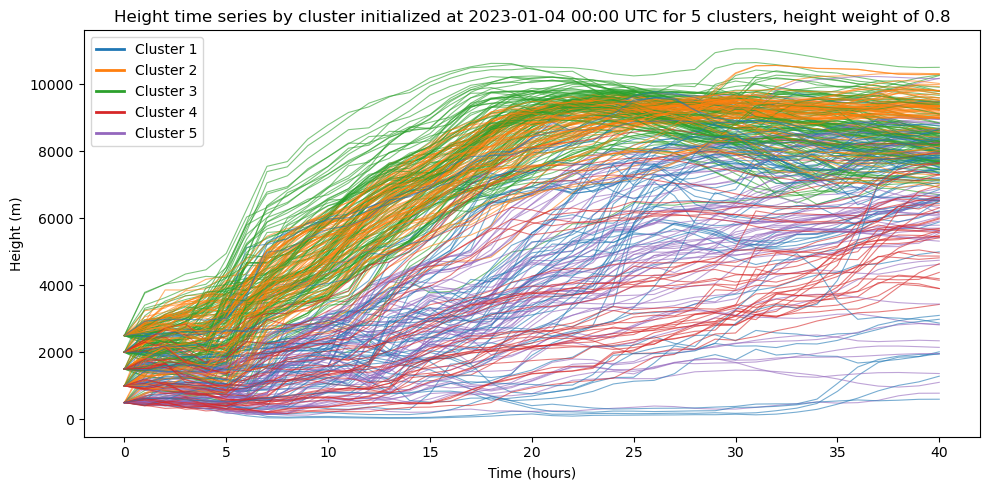

In [26]:
for k in [5]:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    for i, tr in enumerate(all_indices):
        z = ds.z[:, tr].values
    
        # Set up cluster colors
        labels = results[k]
        
        ax.plot(ds.time.values - 24, z, color=cluster_colors[labels[i]], linewidth=0.8, alpha=0.6)
    
    # Legend: only show color indices that appear in this k
    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    ax.legend(handles=legend_elements, loc='upper left', frameon=True)
    ax.set_xlabel('Time (hours)')
    ax.set_ylabel('Height (m)')
    ax.set_title(f'Height time series by cluster initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    plt.tight_layout()
    #####__________#####
    #plt.savefig(f"{init_time}_trajectory_plots_member{member}/height_time_series_clusters_all_heights_{k}_change_in_height,_z_weight={z_weight}.png",
                 #dpi=150, bbox_inches='tight')
    #####__________#####
    #plt.close()

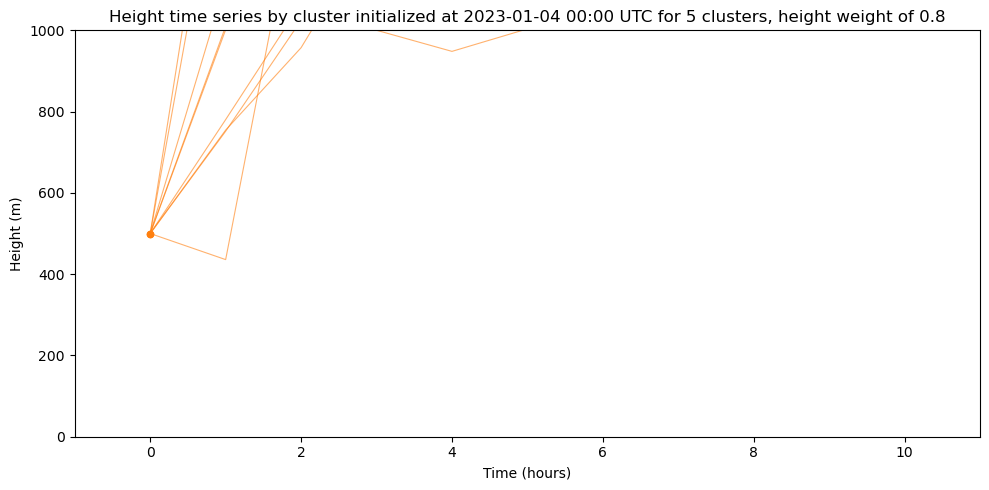

In [27]:
threshold = 0.0004  # PVU

for k in [5]:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    for i, tr in enumerate(all_indices):
        z    = ds.z[:, tr].values
        pv   = ds['total_diabatic_tendency_with_friction'][:, tr].values
        time = ds.time.values - 24

        if z[0] != 500:
            continue
    
        # Set up cluster colors
        labels = results[k]

        if labels[i] != 1:  # cluster 2 is index 1
            continue

        # Only plot points where PV tendency exceeds threshold
        mask = pv > threshold
        
        ax.plot(ds.time.values - 24, z, color=cluster_colors[labels[i]], linewidth=0.8, alpha=0.6)
        ax.scatter(time[mask], z[mask], color=cluster_colors[labels[i]], s=20, alpha=1)
    
    # Legend: only show color indices that appear in this k
    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    #ax.legend(handles=legend_elements, title='Cluster', loc='upper left', frameon=True)
    ax.set_xlabel('Time (hours)')
    ax.set_ylabel('Height (m)')
    ax.set_xlim(-1, 11)
    ax.set_ylim(0,1000)
    ax.set_title(f'Height time series by cluster initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    plt.tight_layout()
    #####__________#####
    # plt.savefig(f"{init_time}_trajectory_plots_member{member}/height_time_series_clusters_all_heights_{k}_change_in_height,_z_weight={z_weight}.png",
    #              dpi=150, bbox_inches='tight')
    #####__________#####
    #plt.close()

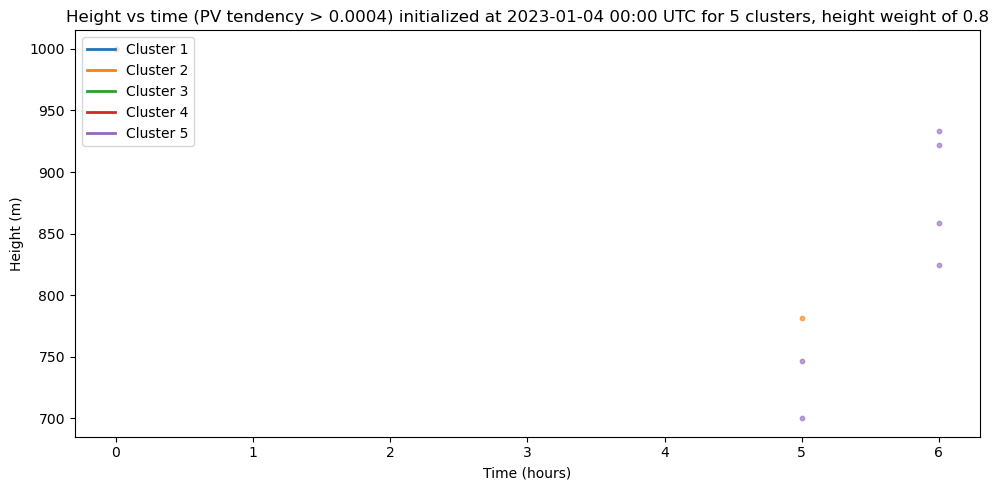

In [28]:
threshold = 0.0004  # PVU

for k in [5]:
    fig, ax = plt.subplots(figsize=(10, 5))

    for i, tr in enumerate(all_indices):
        z    = ds.z[:, tr].values
        pv   = ds['total_diabatic_tendency_with_friction'][:, tr].values
        time = ds.time.values - 24

        if z[0] != 1000:
            continue

        labels = results[k]
        color  = cluster_colors[labels[i]]

        # Only plot points where PV tendency exceeds threshold
        mask = pv > threshold

        ax.scatter(time[mask], z[mask], color=color, s=10, alpha=0.6)

    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    ax.legend(handles=legend_elements, loc='upper left', frameon=True)
    ax.set_xlabel('Time (hours)')
    ax.set_ylabel('Height (m)')
    # ax.set_xlim(-5, 65)
    # ax.set_ylim(-200, 10500)
    ax.set_title(f'Height vs time (PV tendency > {threshold}) initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    plt.tight_layout()
    # plt.savefig(
    #     f"{init_time}_trajectory_plots_member{member}/height_scatter_clusters_all_heights_{k}_pv_threshold,_z_weight={z_weight}.png",
    #     dpi=150, bbox_inches='tight')

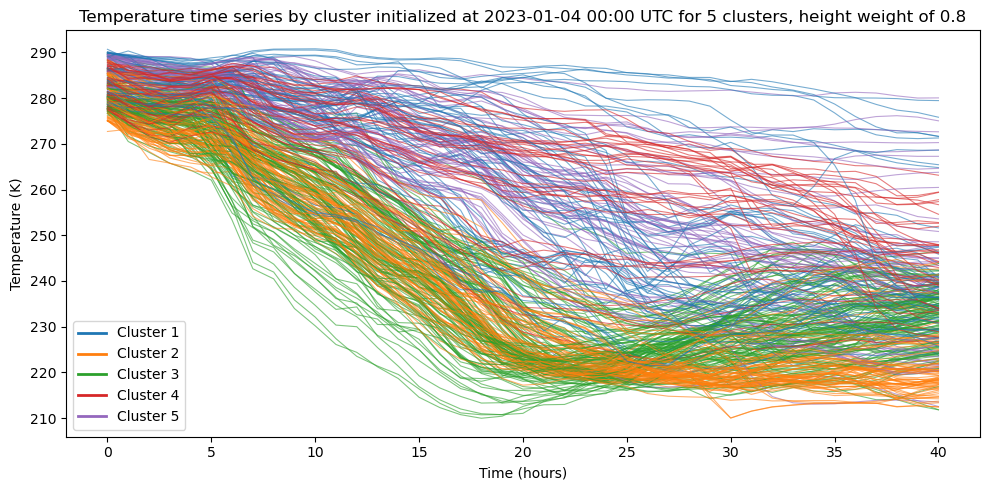

In [29]:
for k in [5]:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    for i, tr in enumerate(all_indices):
        temp = ds.temperature_isobaric[:, tr].values
    
        # Set up cluster colors
        labels = results[k]
        
        ax.plot(ds.time.values - 24, temp, color=cluster_colors[labels[i]], linewidth=0.8, alpha=0.6)
    
    # Legend: only show color indices that appear in this k
    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    ax.legend(handles=legend_elements, loc='lower left', frameon=True)
    ax.set_xlabel('Time (hours)')
    ax.set_ylabel('Temperature (K)')
    ax.set_title(f'Temperature time series by cluster initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    plt.tight_layout()
    #####__________#####
    #plt.savefig(f"{init_time}_trajectory_plots_member{member}/temperature_time_series_clusters_all_heights_{k}_change_in_height,_z_weight={z_weight}.png",
                 #dpi=150, bbox_inches='tight')
    #####__________#####
    #plt.close()

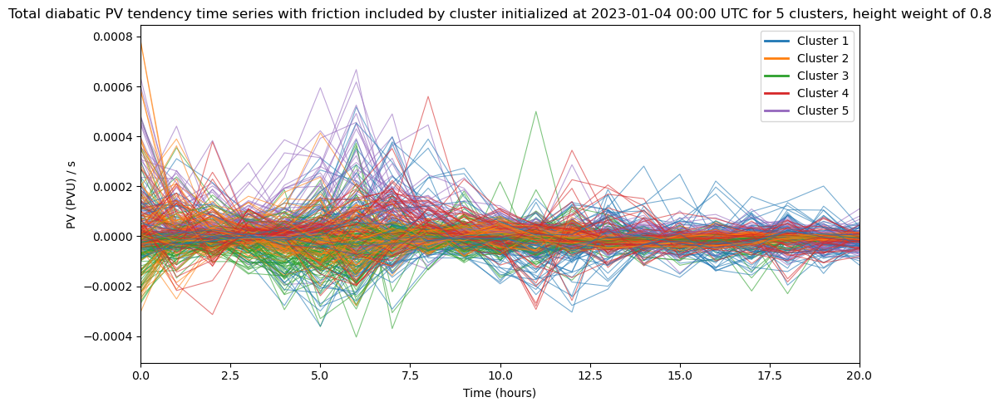

In [30]:
for k in [5]:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    for i, tr in enumerate(all_indices):
        total_diabatic_tendency_with_friction = ds.total_diabatic_tendency_with_friction[:, tr].values
        total_diabatic_tendency = ds.total_diabatic_tendency[:, tr].values
    
        # Set up cluster colors
        labels = results[k]
        
        ax.plot(ds.time.values - 24, total_diabatic_tendency_with_friction, color=cluster_colors[labels[i]], linewidth=0.8, alpha=0.6)
    
    # Legend: only show color indices that appear in this k
    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    ax.legend(handles=legend_elements, loc='upper right', frameon=True)
    ax.set_xlabel('Time (hours)')
    ax.set_ylabel('PV (PVU) / s')
    ax.set_xlim(0, 20)
    ax.set_title(f'Total diabatic PV tendency time series with friction included by cluster initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    #ax.set_title(f'Boundary layer friction component')
    plt.tight_layout()
    #####__________#####
    #plt.savefig(f"{init_time}_trajectory_plots_member{member}/diabatic_pv_time_series_clusters_all_heights_with_friction_{k}_change_in_height,_z_weight={z_weight}.png",
                 #dpi=150, bbox_inches='tight')
    # plt.savefig(f"{init_time}_trajectory_plots_member{member}/boundary_layer_friction_component_all_heights_{k}_change_in_height,_z_weight={z_weight}.png",
    #               dpi=150, bbox_inches='tight')
    #####__________#####
    #plt.close()

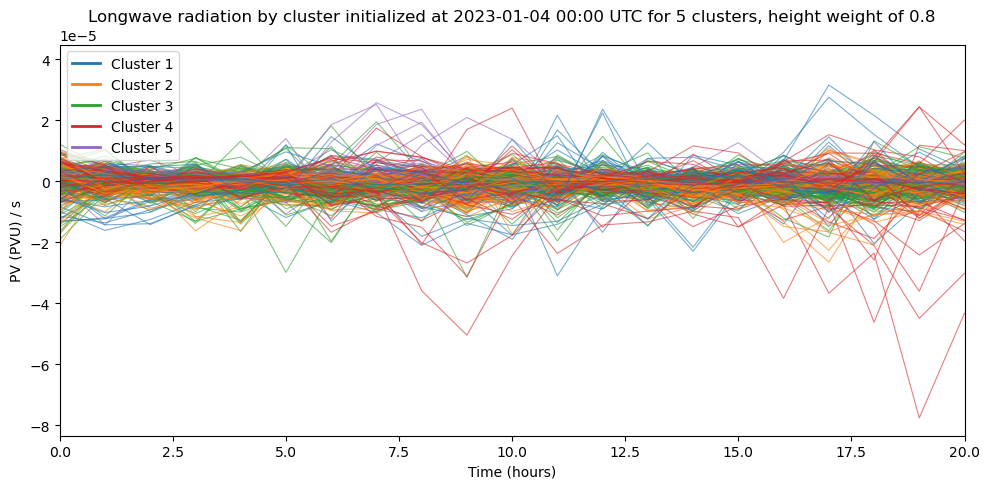

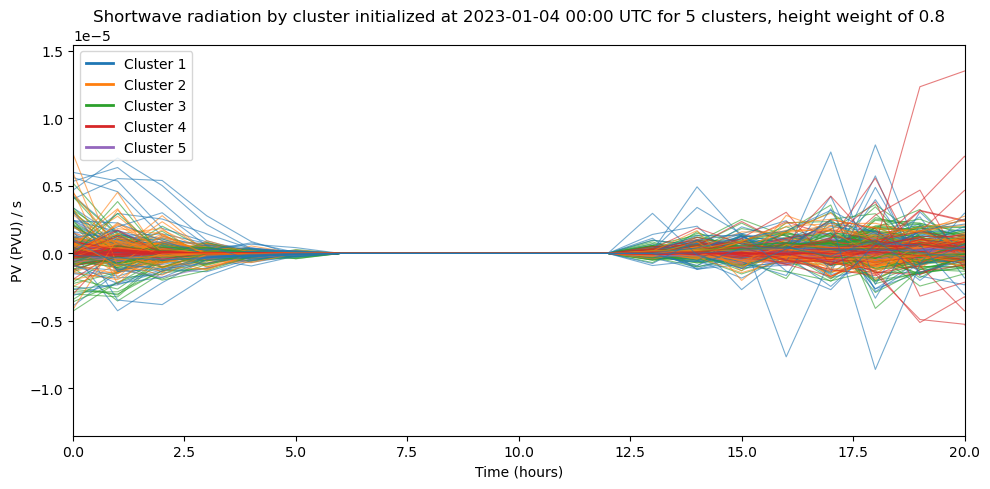

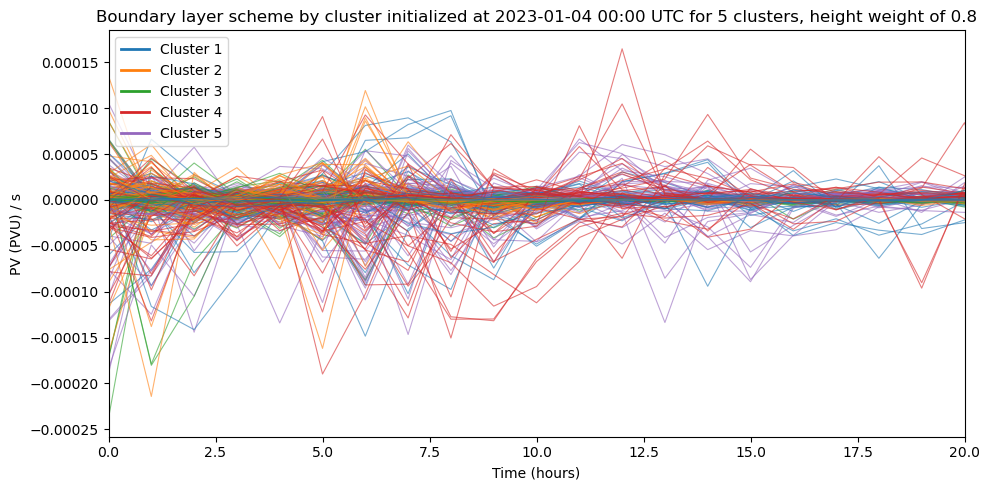

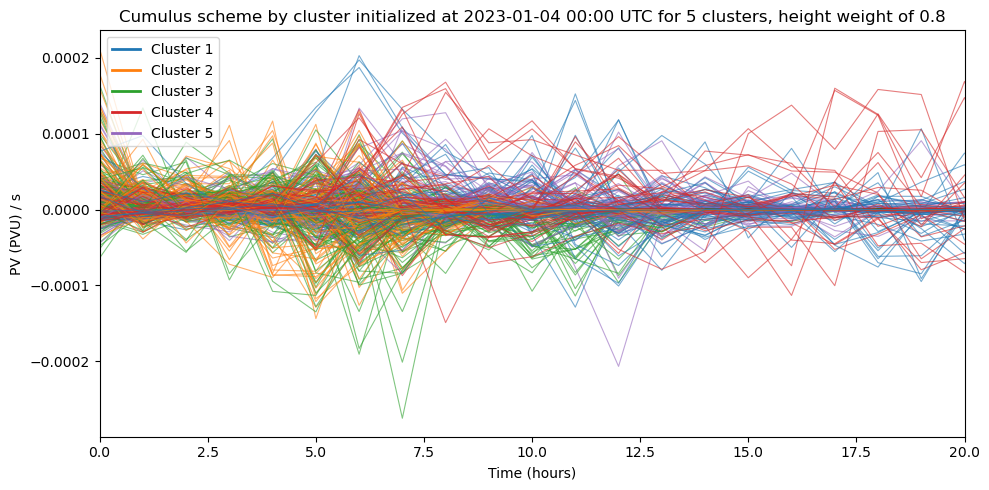

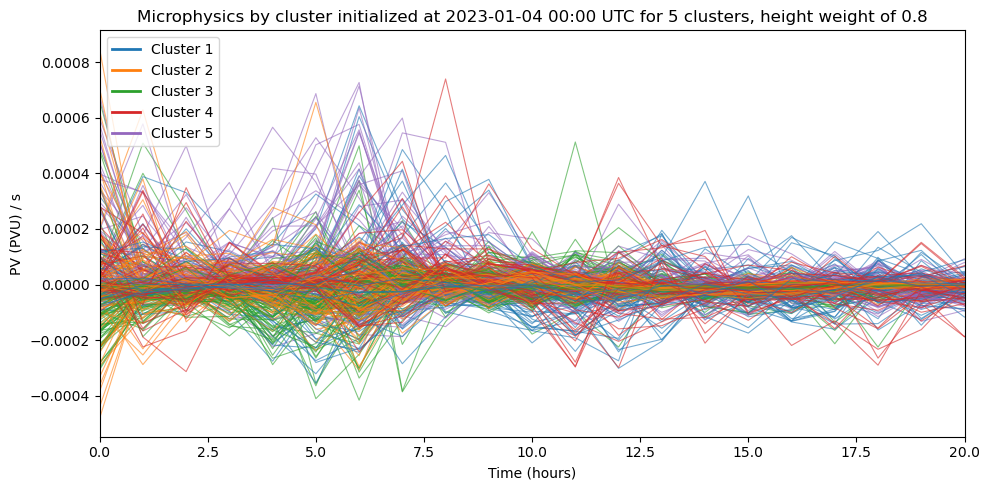

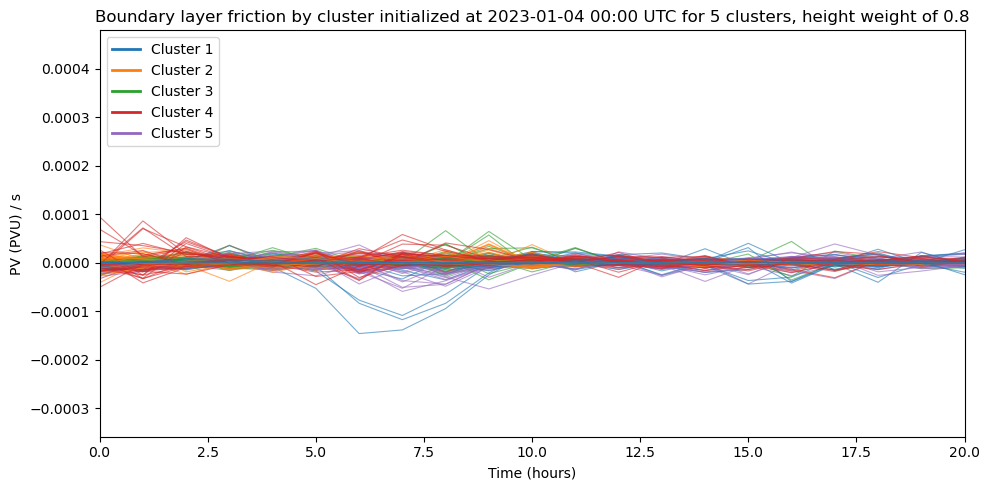

In [31]:
tendency_vars = {
    'acc_depv_dt_lw_isobaric':       'Longwave radiation',
    'acc_depv_dt_sw_isobaric':       'Shortwave radiation',
    'acc_depv_dt_bl_isobaric':       'Boundary layer scheme',
    'acc_depv_dt_cu_isobaric':       'Cumulus scheme',
    'acc_depv_dt_mp_isobaric':       'Microphysics',
    'acc_depv_dt_fric_bl_isobaric':  'Boundary layer friction'
}

for var_name, var_label in tendency_vars.items():
    for k in [5]:
        fig, ax = plt.subplots(figsize=(10, 5))

        for i, tr in enumerate(all_indices):
            var_values = ds[var_name][:, tr].values
            labels = results[k]

            ax.plot(ds.time.values - 24, var_values, color=cluster_colors[labels[i]],
                    linewidth=0.8, alpha=0.6)

        used = sorted(set(labels))
        legend_elements = [
            plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
            for c in used
        ]
        ax.legend(handles=legend_elements, loc='upper left', frameon=True)
        ax.set_xlabel('Time (hours)')
        ax.set_ylabel('PV (PVU) / s')
        ax.set_xlim(0, 20)
        ax.set_title(f'{var_label} by cluster initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
        plt.tight_layout()
        # plt.savefig(
        #     f"{init_time}_trajectory_plots_member{member}/{var_name}_{k}_clusters_z_weight={z_weight}.png",
        #     dpi=150, bbox_inches='tight'
        # )
        #plt.close()

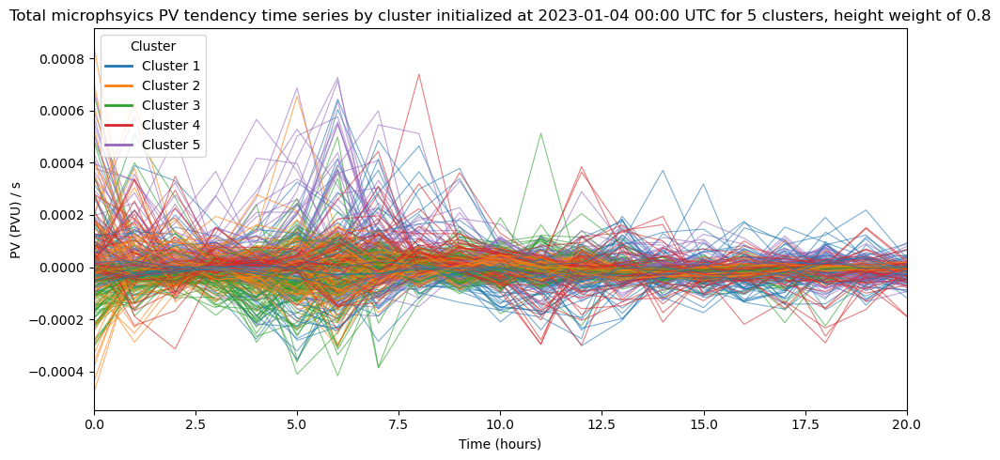

In [32]:
for k in [5]:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    for i, tr in enumerate(all_indices):
        microphysics_tendency = ds.acc_depv_dt_mp_isobaric[:, tr].values
    
        # Set up cluster colors
        labels = results[k]
        
        ax.plot(ds.time.values - 24, microphysics_tendency, color=cluster_colors[labels[i]], linewidth=0.8, alpha=0.6)
    
    # Legend: only show color indices that appear in this k
    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    ax.legend(handles=legend_elements, title='Cluster', loc='upper left', frameon=True)
    ax.set_xlabel('Time (hours)')
    ax.set_ylabel('PV (PVU) / s')
    ax.set_xlim(0, 20)
    ax.set_title(f'Total microphsyics PV tendency time series by cluster initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    plt.tight_layout()
    #####__________#####
    # plt.savefig(f"{init_time}_trajectory_plots_member{member}/microphysics_pv_time_series_clusters_all_heights_{k}_change_in_height,_z_weight={z_weight}.png",
    #              dpi=150, bbox_inches='tight')
    #####__________#####
    #plt.close()

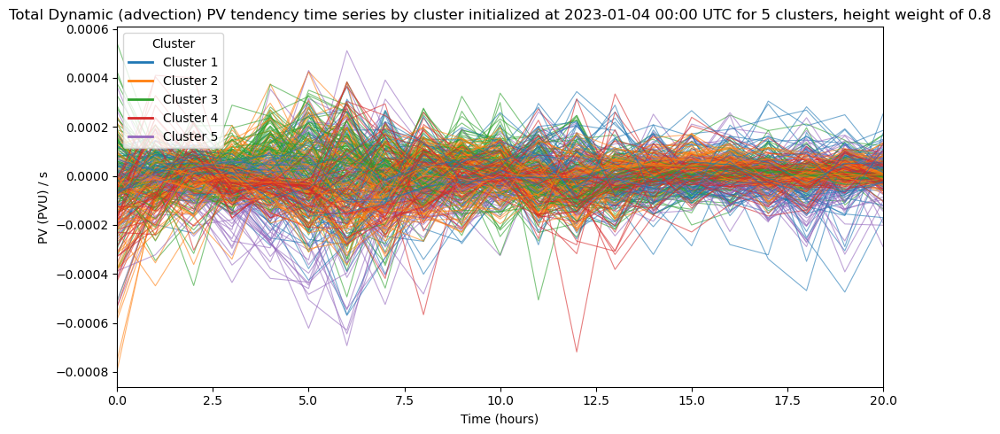

In [33]:
for k in [5]:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    for i, tr in enumerate(all_indices):
        dynamic_tendency = ds.acc_depv_dt_dyn_isobaric[:, tr].values
    
        # Set up cluster colors
        labels = results[k]
        
        ax.plot(ds.time.values - 24, dynamic_tendency, color=cluster_colors[labels[i]], linewidth=0.8, alpha=0.6)
    
    # Legend: only show color indices that appear in this k
    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    ax.legend(handles=legend_elements, title='Cluster', loc='upper left', frameon=True)
    ax.set_xlabel('Time (hours)')
    ax.set_ylabel('PV (PVU) / s')
    ax.set_xlim(0, 20)
    ax.set_title(f'Total Dynamic (advection) PV tendency time series by cluster initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    plt.tight_layout()
    #####__________#####
    # plt.savefig(f"{init_time}_trajectory_plots_member{member}/dynamics_pv_time_series_clusters_all_heights_{k}_change_in_height,_z_weight={z_weight}.png",
    #              dpi=150, bbox_inches='tight')
    #####__________#####
    #plt.close()

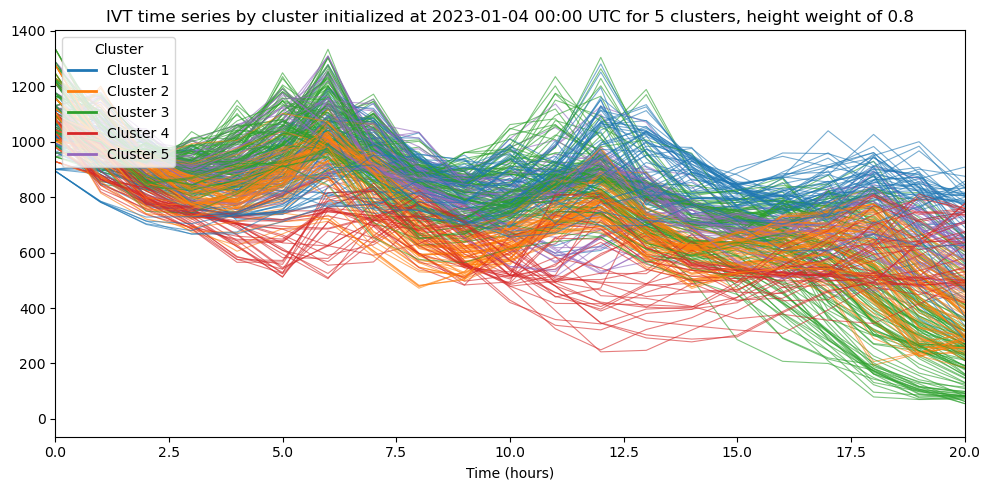

In [34]:
for k in [5]:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    for i, tr in enumerate(all_indices):
        ivt = ds.ivt[:, tr].values
    
        # Set up cluster colors
        labels = results[k]
        
        ax.plot(ds.time.values - 24, ivt, color=cluster_colors[labels[i]], linewidth=0.8, alpha=0.6)
    
    # Legend: only show color indices that appear in this k
    used = sorted(set(labels))
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in used
    ]
    ax.legend(handles=legend_elements, title='Cluster', loc='upper left', frameon=True)
    ax.set_xlabel('Time (hours)')
    #ax.set_ylabel('PV (PVU)')
    ax.set_xlim(0, 20)
    ax.set_title(f'IVT time series by cluster initialized at {formatted_time} for {k} clusters, height weight of {z_weight}')
    plt.tight_layout()
    #####__________#####
    # plt.savefig(f"{init_time}_trajectory_plots_member{member}/ivt_time_series_clusters_all_heights_{k}_change_in_height,_z_weight={z_weight}.png",
    #              dpi=150, bbox_inches='tight')
    #####__________#####
    #plt.close()

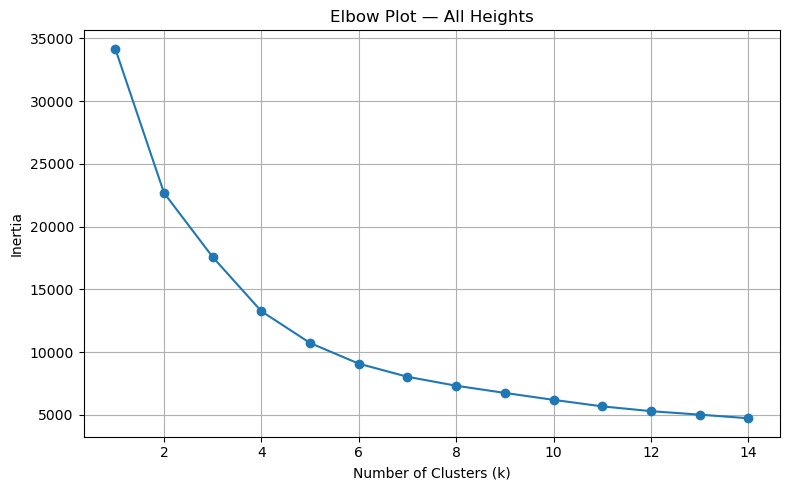

In [35]:
# elbow plot for above clustering code
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

fig, ax = plt.subplots(figsize=(8, 5))

inertias = []
k_range = range(1, 15)  # test up to 14 clusters, adjust as needed

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(features_scaled)
    inertias.append(km.inertia_)

ax.plot(k_range, inertias, 'o-')
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia')
ax.set_title('Elbow Plot — All Heights')
ax.grid(True)
plt.tight_layout()

In [36]:
from scipy.optimize import linear_sum_assignment

def align_labels(labels_ref, labels_new, k):
    """Reorder labels_new to best match labels_ref using the Hungarian algorithm."""
    # Build a cost matrix: cost[i,j] = number of trajectories in cluster i (ref) 
    # that are NOT in cluster j (new)
    cost_matrix = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            cost_matrix[i, j] = np.sum((labels_ref == i) & (labels_new == j))
    
    # Hungarian algorithm finds the best mapping (maximize overlap)
    row_ind, col_ind = linear_sum_assignment(-cost_matrix)  # negative to maximize
    
    # Remap labels_new according to the best mapping
    mapping = {col_ind[i]: row_ind[i] for i in range(k)}
    labels_aligned = np.array([mapping[l] for l in labels_new])
    return labels_aligned

k = 5
z_weights = [1, 0.7, 0.65, 0.6, 0.55, 0.5, 0.45]
labels_by_weight = {}

for zw in z_weights:
    features = flatten(ds, all_indices, z_weight=zw)
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_by_weight[zw] = km.fit_predict(features)

# Align all labels to the z_weight=1 labeling as reference
reference_labels = labels_by_weight[1]
for zw in z_weights:
    labels_by_weight[zw] = align_labels(reference_labels, labels_by_weight[zw], k)

# Now compare — labels are consistent across weights
weight_pairs = [(0.7, 0.65), (0.65, 0.6), (0.6, 0.55), (0.55, 0.5), (0.5, 0.45)]

for w1, w2 in weight_pairs:
    labels1 = labels_by_weight[w1]
    labels2 = labels_by_weight[w2]
    
    changed_mask = labels1 != labels2
    n_changed = changed_mask.sum()
    
    print(f"\nz_weight {w1} → {w2}: {n_changed} trajectories changed cluster")
    
    if n_changed > 0:
        from collections import Counter
        transitions = Counter(zip(labels1[changed_mask], labels2[changed_mask]))
        
        print(f"  {'From → To':<20} {'Count'}")
        print(f"  {'-'*30}")
        for (from_cluster, to_cluster), count in sorted(transitions.items()):
            print(f"  Cluster {from_cluster+1} → Cluster {to_cluster+1}:    {count} trajectories")


z_weight 0.7 → 0.65: 2 trajectories changed cluster
  From → To            Count
  ------------------------------
  Cluster 5 → Cluster 1:    2 trajectories

z_weight 0.65 → 0.6: 6 trajectories changed cluster
  From → To            Count
  ------------------------------
  Cluster 1 → Cluster 5:    2 trajectories
  Cluster 3 → Cluster 1:    2 trajectories
  Cluster 3 → Cluster 5:    2 trajectories

z_weight 0.6 → 0.55: 2 trajectories changed cluster
  From → To            Count
  ------------------------------
  Cluster 3 → Cluster 2:    1 trajectories
  Cluster 5 → Cluster 3:    1 trajectories

z_weight 0.55 → 0.5: 11 trajectories changed cluster
  From → To            Count
  ------------------------------
  Cluster 3 → Cluster 1:    3 trajectories
  Cluster 3 → Cluster 2:    2 trajectories
  Cluster 5 → Cluster 1:    5 trajectories
  Cluster 5 → Cluster 3:    1 trajectories

z_weight 0.5 → 0.45: 0 trajectories changed cluster


## IVT snapshot plots - rerun cells for each time you wish to plot

In [54]:
# Map each date to its file
file_dates = ['2023-01-03_00:00:00', '2023-01-04_00:00:00', '2023-01-05_00:00:00', '2023-01-06_00:00:00',
              '2023-01-07_00:00:00', '2023-01-08_00:00:00']
file_paths = {d: f'member{member_id}_lagranto/latlon.current.{d}.nc' for d in file_dates}

# Pick the right file (just the date portion of your target)
#####__________#####
target_date = '2023-01-04_00:00:00'
#####__________#####
ds_snapshot = xr.open_dataset(file_paths[target_date])

# Select the right time step
#####__________#####
ds_snapshot = ds_snapshot.sel(Time=0)
#####__________#####

In [55]:
ivt = ds_snapshot['ivt']
ertel_pv = ds_snapshot['ertel_pv_isobaric'].isel(nIsoLevels=26)
lat_grid = ds_snapshot['latitude'].values
lon_grid = ds_snapshot['longitude'].values
latent_heat = ds_snapshot['acc_depv_dt_cu_isobaric'].isel(nIsoLevels=23) + ds_snapshot['acc_depv_dt_mp_isobaric'].isel(nIsoLevels=23)
total_tendency = ds_snapshot['acc_depv_dt_lw_isobaric'].isel(nIsoLevels=24) + ds_snapshot['acc_depv_dt_sw_isobaric'].isel(nIsoLevels=24) + ds_snapshot['acc_depv_dt_bl_isobaric'].isel(nIsoLevels=24) + ds_snapshot['acc_depv_dt_cu_isobaric'].isel(nIsoLevels=24) + ds_snapshot['acc_depv_dt_mp_isobaric'].isel(nIsoLevels=24)

#####__________#####
target_hour_since_init = 0
#####__________#####
traj_time_index = np.where(ds.time.values - 24 == target_hour_since_init)[0][0]

ds_snapshot['acc_depv_dt_lw_isobaric'].isel(nIsoLevels=8)


<xarray.DataArray 'acc_depv_dt_lw_isobaric' (latitude: 500, longitude: 2000)> Size: 4MB
[1000000 values with dtype=float32]
Coordinates:
  * latitude   (latitude) float32 2kB 20.05 20.15 20.25 20.35 20.45 20.55 20.65 20.75 20.85 20.95 21.05 21.15 21.25 21.35 21.45 21.55 21.65 21.75 21.85 21.95 22.05 22.15 22.25 22.35 22.45 22.55 22.65 22.75 22.85 22.95 23.05 23.15 23.25 23.35 23.45 23.55 23.65 23.75 23.85 23.95 24.05 24.15 24.25 24.35 24.45 24.55 24.65 24.75 24.85 24.95 25.05 25.15 25.25 25.35 25.45 25.55 25.65 25.75 25.85 25.95 26.05 26.15 26.25 26.35 26.45 26.55 26.65 26.75 26.85 26.95 27.05 27.15 27.25 27.35 27.45 27.55 27.65 27.75 27.85 27.95 28.05 28.15 28.25 28.35 28.45 28.55 28.65 28.75 28.85 28.95 29.05 29.15 29.25 29.35 29.45 29.55 29.65 29.75 29.85 29.95 30.05 30.15 30.25 30.35 30.45 30.55 30.65 30.75 30.85 30.95 31.05 31.15 31.25 31.35 31.45 31.55 31.65 31.75 31.85 31.95 32.05 32.15 32.25 32.35 32.45 32.55 32.65 32.75 32.85 32.95 33.05 33.15 33.25 33.35 33.45 33.55 33.65 33.75 33.85 33.95 34.05 34.15 34.25 34.35 34.45 34.55 34.65 34.75 34.85 34.95 35.05 35.15 35.25 35.35 35.45 35.55 35.65 35.75 35.85 35.95 36.05 36.15 36.25 36.35 36.45 36.55 36.65 36.75 36.85 36.95 37.05 37.15 37.25 37.35 37.45 37.55 37.65 37.75 37.85 37.95 38.05 38.15 38.25 38.35 38.45 38.55 38.65 38.75 38.85 38.95 39.05 39.15 39.25 39.35 39.45 39.55 39.65 39.75 39.85 39.95 40.05 40.15 40.25 40.35 40.45 40.55 40.65 40.75 40.85 40.95 41.05 41.15 41.25 41.35 41.45 41.55 41.65 41.75 41.85 41.95 42.05 42.15 42.25 42.35 42.45 42.55 42.65 42.75 42.85 42.95 43.05 43.15 43.25 43.35 43.45 43.55 43.65 43.75 43.85 43.95 44.05 44.15 44.25 44.35 44.45 44.55 44.65 44.75 44.85 44.95 45.05 45.15 45.25 45.35 45.45 45.55 45.65 45.75 45.85 45.95 46.05 46.15 46.25 46.35 46.45 46.55 46.65 46.75 46.85 46.95 47.05 47.15 47.25 47.35 47.45 47.55 47.65 47.75 47.85 47.95 48.05 48.15 48.25 48.35 48.45 48.55 48.65 48.75 48.85 48.95 49.05 49.15 49.25 49.35 49.45 49.55 49.65 49.75 49.85 49.95 50.05 50.15 50.25 50.35 50.45 50.55 50.65 50.75 50.85 50.95 51.05 51.15 51.25 51.35 51.45 51.55 51.65 51.75 51.85 51.95 52.05 52.15 52.25 52.35 52.45 52.55 52.65 52.75 52.85 52.95 53.05 53.15 53.25 53.35 53.45 53.55 53.65 53.75 53.85 53.95 54.05 54.15 54.25 54.35 54.45 54.55 54.65 54.75 54.85 54.95 55.05 55.15 55.25 55.35 55.45 55.55 55.65 55.75 55.85 55.95 56.05 56.15 56.25 56.35 56.45 56.55 56.65 56.75 56.85 56.95 57.05 57.15 57.25 57.35 57.45 57.55 57.65 57.75 57.85 57.95 58.05 58.15 58.25 58.35 58.45 58.55 58.65 58.75 58.85 58.95 59.05 59.15 59.25 59.35 59.45 59.55 59.65 59.75 59.85 59.95 60.05 60.15 60.25 60.35 60.45 60.55 60.65 60.75 60.85 60.95 61.05 61.15 61.25 61.35 61.45 61.55 61.65 61.75 61.85 61.95 62.05 62.15 62.25 62.35 62.45 62.55 62.65 62.75 62.85 62.95 63.05 63.15 63.25 63.35 63.45 63.55 63.65 63.75 63.85 63.95 64.05 64.15 64.25 64.35 64.45 64.55 64.65 64.75 64.85 64.95 65.05 65.15 65.25 65.35 65.45 65.55 65.65 65.75 65.85 65.95 66.05 66.15 66.25 66.35 66.45 66.55 66.65 66.75 66.85 66.95 67.05 67.15 67.25 67.35 67.45 67.55 67.65 67.75 67.85 67.95 68.05 68.15 68.25 68.35 68.45 68.55 68.65 68.75 68.85 68.95 69.05 69.15 69.25 69.35 69.45 69.55 69.65 69.75 69.85 69.95
  * longitude  (longitude) float32 8kB 150.1 150.2 150.2 150.4 150.4 150.6 150.7 150.8 150.8 150.9 151.0 151.2 151.2 151.4 151.4 151.6 151.7 151.8 151.9 151.9 152.1 152.2 152.2 152.3 152.4 152.6 152.7 152.8 152.9 152.9 153.1 153.2 153.2 153.4 153.4 153.5 153.6 153.8 153.9 153.9 154.1 154.2 154.2 154.4 154.4 154.6 154.7 154.7 154.8 154.9 155.1 155.2 155.2 155.3 155.4 155.6 155.7 155.8 155.9 155.9 156.0 156.1 156.2 156.4 156.4 156.5 156.6 156.8 156.9 156.9 157.1 157.2 157.2 157.4 157.4 157.6 157.7 157.7 157.8 157.9 158.0 158.2 158.2 158.4 158.4 158.6 158.7 158.8 158.9 158.9 159.1 159.2 159.2 159.3 159.4 159.6 159.7 159.8 159.9 159.9 160.1 160.2 160.2 160.4 160.4 160.5 160.7 160.8 160.9 160.9 161.1 161.1 161.2 161.4 161.4 161.6 161.7 161.7 161.8 161.9 162.1 162.2 162.2 162.3 162.4 162.6 162.7 162.8 162.9 162.9 163.0 

/tmp/ipykernel_37284/3039163362.py:24: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for tr in range(ds.dims['ntra']):


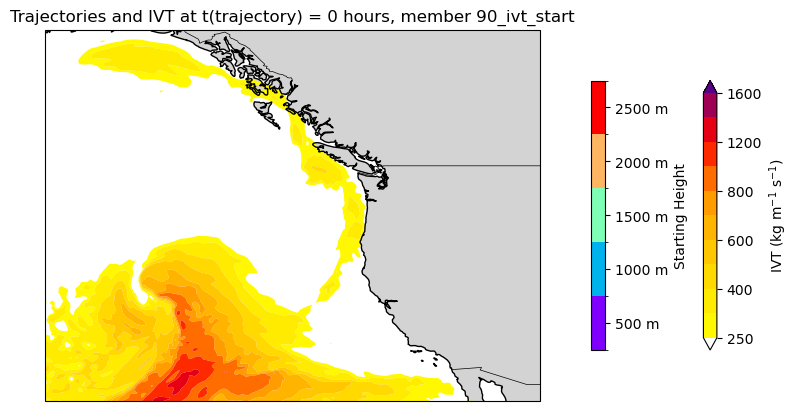

In [56]:
fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray')

height_levels = [500, 1000, 1500, 2000, 2500]

# CW3E color scheme
collist = []
for col in ["#FFFC00","#FFE100","#FFC600","#FFAA00","#FF7D00","#FF4B00","#FF1900","#E60015","#B3003E","#80007B"]:
  collist.append(mcolors.colorConverter.to_rgba(col))
cmap_ivt = mcolors.LinearSegmentedColormap.from_list('rb_cmap', collist)
cmap_ivt.set_under(mcolors.colorConverter.to_rgba('white',alpha = 0.0))
cmap_ivt.set_over(mcolors.colorConverter.to_rgba("#570088"))
cntrs_ivt  = [250., 300., 400., 500., 600., 700., 800., 1000., 1200., 1400., 1600.]

ivt_plot = plt.contourf(lon_grid,lat_grid,ivt,cntrs_ivt,cmap=cmap_ivt,extend='both',antialiased=True,transform=ccrs.PlateCarree())

cbar = plt.colorbar(ivt_plot, ax=ax, orientation='vertical', pad=0.02, shrink=0.5)
cbar.set_label('IVT (kg m$^{-1}$ s$^{-1}$)')

# --- Trajectory points ---
for tr in range(ds.dims['ntra']):
    lat_tr = ds.lat[traj_time_index, tr].values
    lon_tr = ds.lon[traj_time_index, tr].values
    z_tr   = ds.z[0, tr].values

    color = height_cmap(height_norm(z_tr))

    # --- Connecting line from start to current position ---
    lat_line = ds.lat[:traj_time_index+1, tr].values
    lon_line = ds.lon[:traj_time_index+1, tr].values

    ax.plot(lon_line, lat_line, color=color, linewidth=0.8, alpha=0.1,
            transform=ccrs.PlateCarree())

    # ax.scatter(lon_tr, lat_tr,
    #            color=color,
    #            s=60,
    #            edgecolor='k',
    #            linewidth=0.5,
    #            alpha = 0.5,
    #            transform=ccrs.PlateCarree())

# Colorbar for starting height (reuse from before)
sm = plt.cm.ScalarMappable(cmap=height_cmap, norm=height_norm)
sm.set_array([])
cbar2 = plt.colorbar(sm, ax=ax, orientation='vertical', pad=0.08, shrink=0.5)
cbar2.set_ticks(height_levels)
cbar2.set_ticklabels([f'{h} m' for h in height_levels])
cbar2.set_label('Starting Height')

#####__________#####
ax.set_extent([-110, -150, 30, 60], crs=ccrs.PlateCarree())
#####__________#####
ax.set_title(f"Trajectories and IVT at t(trajectory) = {target_hour_since_init} hours, member {member}")
plt.savefig(f"{init_time}_trajectory_plots_member{member}/trajectories_with_ivt_{target_hour_since_init}.png")
#plt.close(fig)

In [ ]:
starting_height_levels = [500, 1000, 1500, 2000, 2500]
point_height_levels = [0,2000,4000,6000,8000,10000]
starting_height_cmap = plt.cm.rainbow
point_height_cmap = plt.cm.jet
starting_height_norm = mcolors.BoundaryNorm(boundaries=[250, 750, 1250, 1750, 2250, 2750], ncolors=256)
point_height_norm = mcolors.BoundaryNorm(boundaries=[0,2000,4000,6000,8000,10000], ncolors=256)

colorlist = ('#FFFFFF', '#654CFF', '#5882FA', '#A9BCF5', '#E0ECF8', '#F8E0E0', '#F5A9A9', '#FF0000', '#FF99BF')
cmap = matplotlib.colors.ListedColormap(colorlist)
levels = np.linspace(-0.002, 0.002, 21)  # 21 levels -> 20 bands, ±0.002 range

start_index = np.argmin(np.abs(ds_snapshot.iso_levels.values - 30000))

# Compute cluster labels before the loop
all_indices = np.arange(ds.dims['ntra'])
features = flatten(ds, all_indices, z_weight=0.3)
km = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = km.fit_predict(features)

cluster_cmap = plt.cm.tab10
cluster_colors = [cluster_cmap(i) for i in range(10)]

# Find the 950 hPa level index
target_level_pa = 95000  # 950 hPa in Pa
i = np.argmin(np.abs(ds_snapshot.iso_levels.values - target_level_pa))

fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray')

# Tendencies
mp_tendency = ds_snapshot['acc_depv_dt_mp_isobaric'].isel(nIsoLevels=i)
theta_mp_tendency = ds_snapshot['acc_dtheta_dt_mp_isobaric'].isel(nIsoLevels=i)
bl_tendency = ds_snapshot['acc_depv_dt_bl_isobaric'].isel(nIsoLevels=i)
fric_bl_tendency = ds_snapshot['acc_depv_dt_fric_bl_isobaric'].isel(nIsoLevels=i)

pv_plot = ax.contourf(
    lon_grid, lat_grid, fric_bl_tendency,
    levels=levels, cmap='bwr', extend='both',
    antialiased=True, transform=ccrs.PlateCarree()
)
cbar = plt.colorbar(pv_plot, ax=ax, orientation='vertical', pad=0.02, shrink=0.5)
cbar.set_label('PV (PVU) / s')

# Filter trajectories: cluster 2 (index 1) AND starting height 500m
traj_pressure = ds.pressure[traj_time_index, :].values
iso_levels_pa = ds_snapshot.iso_levels.values
closest_level_indices = np.argmin(
    np.abs(traj_pressure[:, np.newaxis] - iso_levels_pa[np.newaxis, :]),
    axis=1
)

level_mask       = closest_level_indices == i          # at 950 hPa
cluster_mask     = labels == 1                         # cluster 2 (0-indexed)
start_height_mask = ds.z[0, :].values == 500.0        # starting height 500m

combined_mask = cluster_mask & start_height_mask

for tr in np.where(cluster_mask)[0]:
    lat_tr = ds.lat[traj_time_index, tr].values
    lon_tr = ds.lon[traj_time_index, tr].values
    color  = cluster_colors[labels[tr]]

    lat_line = ds.lat[:traj_time_index+1, tr].values
    lon_line = ds.lon[:traj_time_index+1, tr].values

    ax.plot(lon_line, lat_line, color=color, linewidth=0.8, alpha=0.05,
            transform=ccrs.PlateCarree())
    ax.scatter(lon_tr, lat_tr,
               color=color,
               s=60,
               edgecolor='k',
               linewidth=0.1,
               alpha=0.5,
               transform=ccrs.PlateCarree())

ax.set_extent([-125, -138, 30, 40], crs=ccrs.PlateCarree())
ax.set_title(
    f"Cluster 2 (500m start) trajectories and 950 hPa boundary layer friction scheme "
    f"PV tendency at t(trajectory) = {target_hour_since_init} hours, member {member}"
)
# plt.savefig(
#     f"{init_time}_trajectory_plots_member{member}/cluster2_500m_start_fric_bl_tendency_950hpa_{target_hour_since_init}.png",
#     bbox_inches='tight'
# )

In [ ]:
for i in range(start_index, len(ds_snapshot.iso_levels.values)):
    fig = plt.figure(figsize=(10, 7))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray')

    current_level_pa = ds_snapshot.iso_levels.values[i]

    total_tendency = (
        ds_snapshot['acc_depv_dt_lw_isobaric'].isel(nIsoLevels=i)
        + ds_snapshot['acc_depv_dt_sw_isobaric'].isel(nIsoLevels=i)
        + ds_snapshot['acc_depv_dt_bl_isobaric'].isel(nIsoLevels=i)
        + ds_snapshot['acc_depv_dt_cu_isobaric'].isel(nIsoLevels=i)
        + ds_snapshot['acc_depv_dt_mp_isobaric'].isel(nIsoLevels=i)
    )

    pv_plot = ax.contourf(
        lon_grid, lat_grid, total_tendency,
        levels=levels, cmap='bwr', extend='both',
        antialiased=True, transform=ccrs.PlateCarree()
    )

    cbar = plt.colorbar(pv_plot, ax=ax, orientation='vertical', pad=0.02, shrink=0.5)
    cbar.set_label('PV (PVU) / s')

    # Get pressure of all trajectories at the target time step
    traj_pressure = ds.pressure[traj_time_index, :].values
    iso_levels_pa = ds_snapshot.iso_levels.values
    closest_level_indices = np.argmin(
        np.abs(traj_pressure[:, np.newaxis] - iso_levels_pa[np.newaxis, :]),
        axis=1
    )
    level_mask = closest_level_indices == i

    for j, tr in enumerate(np.where(level_mask)[0]):
        lat_tr = ds.lat[traj_time_index, tr].values
        lon_tr = ds.lon[traj_time_index, tr].values

        color = cluster_colors[labels[tr]]  # use tr directly to index into labels

        # Connecting line from start to current position
        lat_line = ds.lat[:traj_time_index+1, tr].values
        lon_line = ds.lon[:traj_time_index+1, tr].values

        ax.plot(lon_line, lat_line, color=color, linewidth=0.8, alpha=0.4,
                transform=ccrs.PlateCarree())

        ax.scatter(lon_tr, lat_tr,
                   color=color,
                   s=60,
                   edgecolor='k',
                   linewidth=0.5,
                   alpha=0.6,
                   transform=ccrs.PlateCarree())

    # Cluster legend
    legend_elements = [
        plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
        for c in range(5)
    ]
    ax.legend(handles=legend_elements, loc='upper right', frameon=True)

    ax.set_extent([-127, -138, 31, 42], crs=ccrs.PlateCarree())
    ax.set_title(
        f"Trajectories and {ds_snapshot.iso_levels.values[i]/100} hPa total diabatic "
        f"PV tendency at t(trajectory) = {target_hour_since_init} hours, member {member}"
    )
    # plt.savefig(
    #     f"{init_time}_trajectory_plots_member{member}/trajectories_with_pv_tendency_"
    #     f"{target_hour_since_init}_{ds_snapshot.iso_levels.values[i]/100}hpa.png",
    #     bbox_inches='tight'
    # )
    #plt.close(fig)

In [ ]:
ds.z[0, :].values

## Backward trajectory addendum

In [ ]:
ds_backward = xr.open_dataset('member9_lagranto/backward_member9_24_hr_2023010300.nc')  # adjust filename

fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='white')
ax.add_feature(cfeature.LAKES, facecolor='white')
ax.set_extent([-120, -180, 15, 40], crs=ccrs.PlateCarree())

for i, tr in enumerate(all_indices):
    lat = ds_backward.lat[:, tr].values
    lon = ds_backward.lon[:, tr].values

    ax.plot(lon, lat, color=cluster_colors[labels[i]],
            linewidth=0.8, alpha=0.6, transform=ccrs.PlateCarree())

legend_elements = [
    plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
    for c in range(k)
]
ax.legend(handles=legend_elements, title='Cluster', loc='lower left', frameon=True)
ax.set_title(f'Backward Trajectory Clusters (all heights) initialized at {formatted_time} for {k} clusters')
#plt.savefig(f"{init_time}_trajectory_plots_member{member}/backward_trajectory_clusters_{k}.png",
            #dpi=150, bbox_inches='tight')
plt.show()
#plt.close(fig)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

for i, tr in enumerate(all_indices):
    z = ds_backward.z[:, tr].values
    color = cluster_colors[labels[i]]
    ax.plot(ds_backward.time.values - 24, z, color=color, linewidth=0.8, alpha=0.6)

# # Cluster mean height
# for cluster_id in range(k):
#     cluster_mask = labels == cluster_id
#     cluster_traj_indices = all_indices[cluster_mask]
#     mean_z = ds_backward.z[:, cluster_traj_indices].values.mean(axis=1)
#     ax.plot(ds_backward.time.values - 24, mean_z, color=cluster_colors[cluster_id],
#             linewidth=3, alpha=1.0, linestyle='--')

legend_elements = [
    plt.Line2D([0], [0], color=cluster_colors[c], linewidth=2, label=f'Cluster {c+1}')
    for c in range(k)
]
ax.legend(handles=legend_elements, title='Cluster', loc='upper left', frameon=True)
ax.set_xlabel('Time (hours)')
ax.set_ylabel('Height (m)')
ax.set_title(f'Backward trajectory height time series by cluster initialized at {formatted_time}')
plt.tight_layout()
#plt.savefig(f"{init_time}_trajectory_plots_member{member}/backward_height_time_series_clusters_{k}.png",
            #dpi=150, bbox_inches='tight')
plt.show()
#plt.close(fig)